# 07 · Team style

A player plays in a team: how the team presses, keeps the ball and moves it forward shapes what
the player does, and a signing has to fit the team that buys them. This notebook describes how
the 80 teams of the four leagues play, then reads players within their team.

1. **How a team plays.** Which numbers describe a team's play, measured reliably and on one scale
   across leagues.
2. **Team style axes.** How the teams differ, in a few named directions.
3. **Players within teams.** How much of a player's style is the team's, and whether the players
   who changed team in January changed style with it.
4. **Fit.** How well a player fits a team, and whether the players who changed club for 2016/17
   played more where they fitted.
5. **Against which opponents** (an addendum). Whether a player's numbers depend on the
   opponent's style, so that a line-up could be fitted to it.

**Teams:** the 80 teams of the Premier League, La Liga, Serie A and Ligue 1, 2015/16, each over
its 37 or 38 league matches.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups), 2015/16,
the four complete leagues; points per match from the results; for section 4, Transfermarkt's
market values, appearances, transfers and coaches. Only aggregated results are shown, as
StatsBomb's licence requires. Tables are built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mplsoccer import Pitch
from scipy import sparse

from football_scouting.analysis.leagues import eta_squared, team_effect
from football_scouting.analysis.market import team_strength
from football_scouting.analysis.outcomes import (
    club_leagues,
    coaches,
    first_half_clubs,
    league_share,
)
from football_scouting.analysis.profiles import LABELS as PROFILE_LABELS
from football_scouting.analysis.profiles import (
    POSSESSION,
    RELIABILITY_MINUTES,
    match_counts,
    recording_context,
    summed_columns,
    towards,
)
from football_scouting.analysis.profiles import place as place_profile
from football_scouting.analysis.profiles import rescale as rescale_players
from football_scouting.analysis.roles import (
    axes_of,
    congruence,
    fit_axes,
    parallel_analysis,
    place,
    retained,
    style_matches,
)
from football_scouting.analysis.similarity import fit_block
from football_scouting.analysis.style import LABELS, NAMES, SUMMED, descriptors
from football_scouting.analysis.teams import (
    LONG_GOAL_KICK,
    NUMBERS,
    fit,
    fit_distances,
    numbers,
    pass_network,
    position_code,
    scores_without,
    split_half,
    style_axes,
    style_slopes,
    team_seasons,
    whole_season_team,
)
from football_scouting.analysis.values import pool_valuations, value_at
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()

LEAGUE_OF = {c.competition_id: c.name for c in cfg.statsbomb.competitions}
LEAGUES = sorted(c.name for c in cfg.statsbomb.competitions if c.scouting_pool)
LEAGUE_COLORS = dict(
    zip(LEAGUES, [OKABE_ITO[0], OKABE_ITO[5], OKABE_ITO[3], OKABE_ITO[2]], strict=True)
)
DRAWS, SEED = 200, 2016
SOURCE = "Data: StatsBomb Open Data (2015/16)"

## 1. How a team plays

Fourteen numbers describe a team's play without the ball (PPDA, the height of its defensive
actions, how much of its pressing is in the final third and how much is counterpressing) and with
it (possession, field tilt, passes per possession, tempo, directness, long balls from the back
and from goal kicks, wide entries into the final third, crosses, and the risk its passing takes).
Their definitions are in `analysis.teams`; each is a ratio of sums over a team's matches.

- **Recording.** Tackles, interceptions, fouls, clearances and pressures are recorded differently
  between leagues and, in the Premier League, from match week 19 (notebook 01, section 3). Within
  each recording context they are rescaled so that their mean per team-match equals the mean over
  every context, each context keeping the heights of its actions. What a league's teams do
  differently on those counts goes with the rescaling: PPDA compares a team's pressing with its
  league's.
- **Reliability.** Each team's matches are shuffled and dealt alternately into two halves (200
  draws); each half's numbers, centred within the league, are correlated across the 80 teams and
  stepped up to a whole season (Spearman-Brown).
- **The league and strength.** How much of each number the league explains (η² across the
  teams), and how it follows a team's points per match (Spearman).
- **The rule**, fixed before any result: a number is kept if its reliability is 0.7 or more; of
  two numbers at a Spearman correlation of 0.8 or more (either sign) across the teams, the more
  reliable is kept, the pairs taken from the most correlated down.

### 1.1 On one scale

In [2]:
seasons = team_seasons(con, cfg)  # every team's and player's counts, on one scale
sums, context, factors = seasons.recorded, seasons.context, seasons.factors
adjusted, season_sums = seasons.matches, seasons.season
league = sums.groupby("team_id").competition_id.first().map(LEAGUE_OF).rename("league")
season = numbers(season_sums)
team_names = con.sql("SELECT DISTINCT team_id, team_name FROM teams").df().set_index("team_id")

CONTEXTS = sorted(context.unique())
table = factors.pivot(index="statistic", columns="context", values="factor")[CONTEXTS]
ppda = {}
for name, rows in {"PPDA as recorded": sums, "PPDA on one scale": adjusted}.items():
    per_team = numbers(rows.groupby([context.to_numpy(), rows.team_id]).sum(numeric_only=True))
    ppda[name] = per_team.ppda.groupby(level=0).mean()
table = pd.concat([table, pd.DataFrame(ppda).T[CONTEXTS]])
display(
    table.style.format("{:.2f}")
    .set_caption("Recording factors by context (counts are multiplied by them), and PPDA, the "
                 "mean over each context's teams")
)  # fmt: skip
kicks = (
    con.sql(
        "SELECT length FROM passes JOIN matches USING (match_id) "
        "WHERE scouting_pool AND pass_type = 'Goal Kick'"
    )
    .df()
    .length
)
long_kick = kicks >= LONG_GOAL_KICK
print(
    f"{len(sums):,} team-matches, {sums.team_id.nunique()} teams. Goal kicks: {len(kicks):,}, "
    f"{(~long_kick).mean():.0%} under {LONG_GOAL_KICK} yards (median "
    f"{kicks[~long_kick].median():.0f}), {long_kick.mean():.0%} at {LONG_GOAL_KICK} or more "
    f"(median {kicks[long_kick].median():.0f}); {kicks.between(35, 45).mean():.0%} between 35 "
    "and 45 yards."
)

,La Liga,Ligue 1,Premier League before 2015-12-28,Premier League from 2015-12-28,Serie A
clearances,1.13,1.04,0.92,0.79,1.03
counterpressures,1.03,0.94,1.14,1.01,0.97
fouls_high,0.93,1.01,1.24,1.26,0.88
interceptions,0.76,1.09,2.10,0.73,1.21
interceptions_high,0.75,1.09,2.03,0.75,1.22
pressures,1.08,0.93,1.17,0.99,0.94
pressures_final_third,1.06,0.95,1.22,1.01,0.91
tackles,1.00,0.95,0.97,0.98,1.08
tackles_high,1.00,0.95,0.99,0.99,1.07
PPDA as recorded,11.57,13.99,15.83,12.67,13.02


3,034 team-matches, 80 teams. Goal kicks: 25,281, 21% under 40 yards (median 24), 79% at 40 or more (median 65); 4% between 35 and 45 yards.


### 1.2 The numbers

In [3]:
reliability = split_half(adjusted, league, draws=DRAWS, seed=SEED)
points = team_strength(con).set_index("team_id").points.loc[season.index]
summary = season.groupby(league).mean().T[LEAGUES].rename_axis(columns=None)
summary["Reliability"] = reliability.mean()
summary["Lowest 2.5%"] = reliability.quantile(0.025)
summary["League η²"] = [eta_squared(season[n], league) for n in season]
summary["Spearman with points"] = season.corrwith(points, method="spearman")


def short(n):
    """A number's name in a sentence ("PPDA", "pass ease")."""
    name = NUMBERS[n].split(" (")[0]
    return name if name.isupper() else name.lower()


rho = season.corr(method="spearman")
kept = [n for n in season if summary.at[n, "Reliability"] >= 0.7]
upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
dropped = {}
for (a, b), r in upper.abs().sort_values(ascending=False).items():
    if r < 0.8:
        break
    if a in kept and b in kept:
        less = summary.at[a, "Reliability"] < summary.at[b, "Reliability"]
        out, stays = (a, b) if less else (b, a)
        kept.remove(out)
        dropped[out] = (stays, upper[a, b])
TEAM_NUMBERS = list(cfg.team_style.numbers)
assert kept == TEAM_NUMBERS  # as configured (`team_style.numbers`)
summary["Kept"] = ["yes" if n in kept else f"no: {short(dropped[n][0])} "
                   f"({dropped[n][1]:+.2f})" if n in dropped else "no: unreliable"
                   for n in summary.index]  # fmt: skip
summary.index = [NUMBERS[n] for n in summary.index]
display(
    summary.style.format("{:.2f}", subset=[*LEAGUES, "Reliability", "Lowest 2.5%", "League η²",
                                           "Spearman with points"])
    .set_caption("The team numbers over the 80 teams: league means, reliability over a season "
                 "(mean of 200 draws, and the lowest 2.5%), what the league explains, how they "
                 "follow points per match; a number dropped by the rule names the number kept "
                 "and their Spearman correlation")
)  # fmt: skip
print(f"Kept by the rule: {len(kept)} of {len(NUMBERS)}: "
      + ", ".join(short(n) for n in kept) + ".")  # fmt: skip

,La Liga,Ligue 1,Premier League,Serie A,Reliability,Lowest 2.5%,League η²,Spearman with points,Kept
PPDA (opponent passes per defensive action),12.73,13.95,12.59,13.08,0.82,0.75,0.09,-0.48,yes
Height of defensive actions (x),42.28,42.71,42.83,42.54,0.82,0.76,0.01,0.63,yes
Final-third pressures per pressure,0.20,0.20,0.20,0.20,0.81,0.76,0.00,0.51,yes
Counterpressures per pressure,0.21,0.21,0.21,0.21,0.84,0.78,0.00,0.49,yes
Possession (share of the time with the ball),0.50,0.50,0.50,0.50,0.94,0.91,0.00,0.63,no: pass ease (+0.84)
Field tilt (share of final-third passes),0.50,0.50,0.50,0.50,0.91,0.89,0.00,0.66,no: possession (+0.89)
Passes per possession,4.30,4.47,4.58,4.38,0.97,0.96,0.02,0.63,no: pass ease (+0.89)
Passes per minute with the ball,12.09,12.26,12.17,12.03,0.96,0.95,0.01,0.60,no: passes per possession (+0.93)
Yards gained per completed pass,3.93,4.15,3.65,3.95,0.94,0.91,0.07,-0.43,yes
Long passes per pass from the own third,0.32,0.28,0.32,0.28,0.95,0.94,0.19,-0.51,yes


Kept by the rule: 10 of 14: PPDA, height of defensive actions, final-third pressures per pressure, counterpressures per pressure, yards gained per completed pass, long passes per pass from the own third, long goal kicks per goal kick, wide entries into the final third, crosses per final-third pass, pass ease.


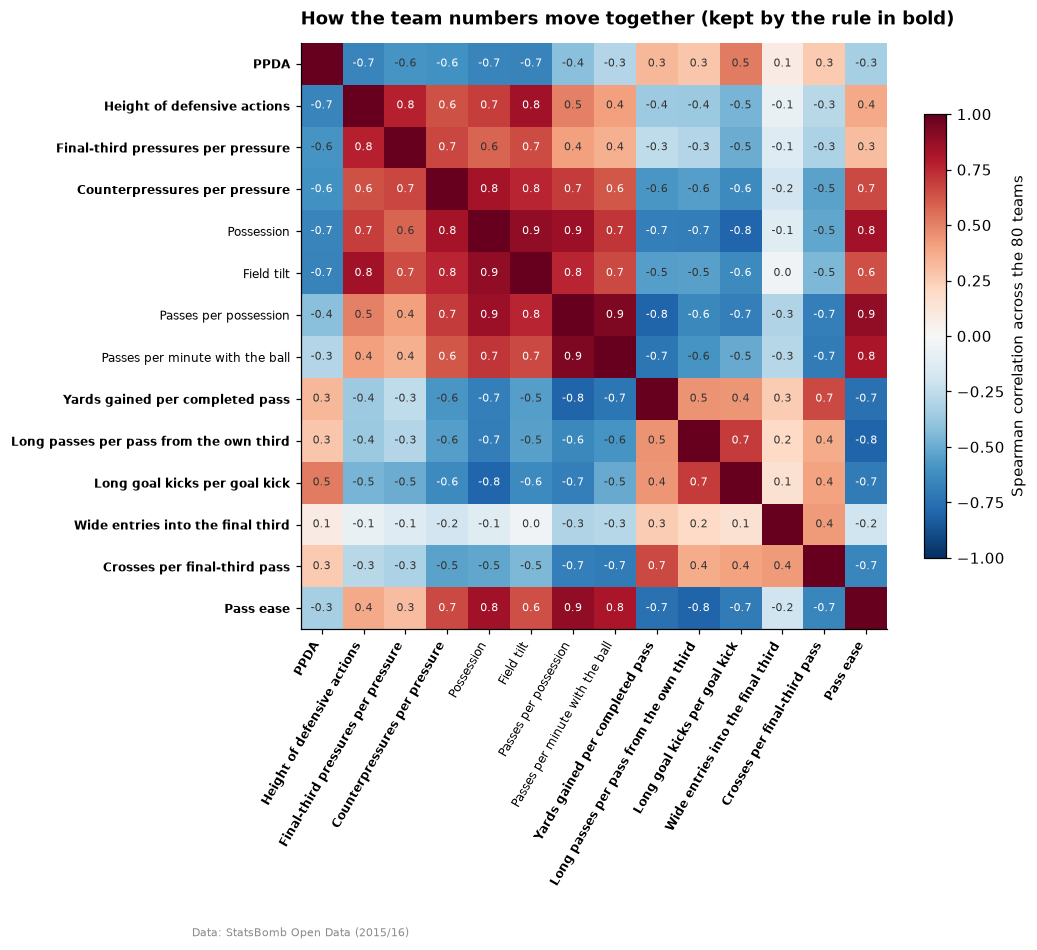

In [4]:
order = list(NUMBERS)
fig, ax = plt.subplots(figsize=(8.6, 8.6))
fig.subplots_adjust(bottom=0.27, top=0.94)
image = ax.imshow(rho.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            value = rho.loc[order[i], order[j]]
            ax.text(j, i, f"{value:.1f}".replace("-0.0", "0.0"), ha="center", va="center",
                    fontsize=7, color="white" if abs(value) >= 0.6 else "#333333")  # fmt: skip
labels = [NUMBERS[n].split(" (")[0] for n in order]
ax.set_xticks(range(len(order)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(order)), labels, fontsize=8)
for tick in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
    if order[labels.index(tick.get_text())] in kept:
        tick.set_fontweight("bold")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7, label="Spearman correlation across the 80 teams")
ax.set_title("How the team numbers move together (kept by the rule in bold)", pad=12)
credit(fig, SOURCE)
plt.show()

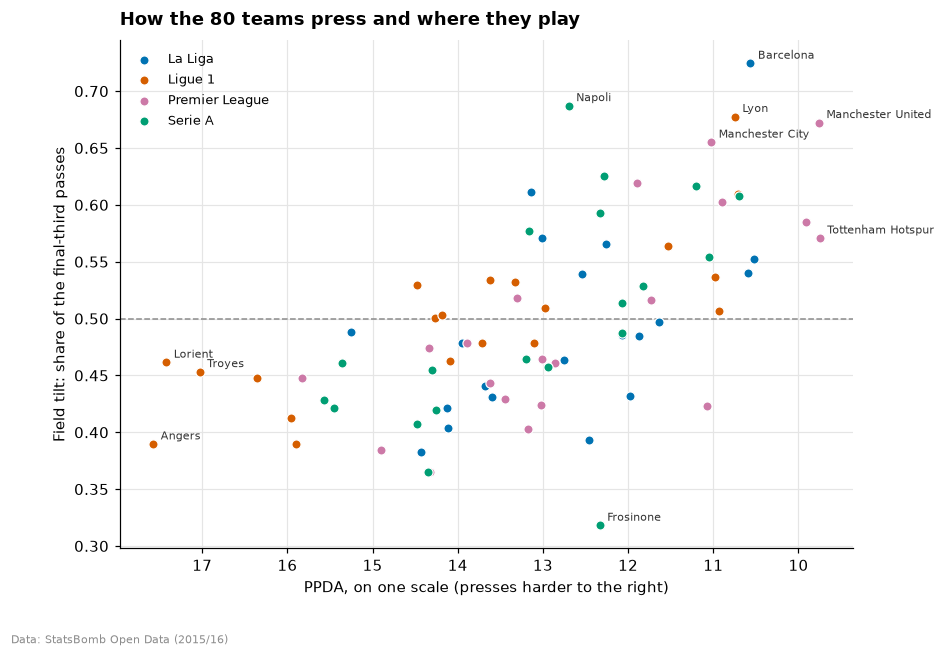

Spearman between PPDA and field tilt across the teams: -0.67.


In [5]:
fig, ax = plt.subplots(figsize=(8.6, 6))
for name in LEAGUES:
    teams_in = season.index[league == name]
    ax.scatter(season.ppda[teams_in], season.field_tilt[teams_in], s=36, label=name,
               color=LEAGUE_COLORS[name], edgecolor="white", linewidth=0.8, zorder=3)  # fmt: skip
z = (season[["ppda", "field_tilt"]] - season[["ppda", "field_tilt"]].mean()) / season[
    ["ppda", "field_tilt"]
].std()
for team in z.pow(2).sum(axis=1).nlargest(10).index:
    ax.annotate(team_names.team_name[team], (season.ppda[team], season.field_tilt[team]),
                xytext=(5, 3), textcoords="offset points", fontsize=7.5,
                color="#333333")  # fmt: skip
ax.axhline(0.5, color=GREY, lw=1, ls="--")
ax.invert_xaxis()
ax.set_xlabel("PPDA, on one scale (presses harder to the right)")
ax.set_ylabel("Field tilt: share of the final-third passes")
ax.set_title("How the 80 teams press and where they play", pad=10)
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(color="#E5E5E5")
credit(fig, SOURCE)
plt.show()
print(f"Spearman between PPDA and field tilt across the teams: "
      f"{season.ppda.corr(season.field_tilt, method='spearman'):+.2f}.")  # fmt: skip

### What section 1 shows

- **Ten numbers describe a team's play.** All fourteen tell teams apart reliably over a season
  (0.81 to 0.97), and the rule drops four that move with others: tempo with passes per possession
  (ρ 0.93), field tilt with possession (0.89), passes per possession and possession with pass
  ease (0.89 and 0.84). Pass ease, the mean expected completion of a team's passes, stands for the
  possession game: the teams that keep the ball play the safer passes. Kept: PPDA, the height of
  defensive actions, final-third pressures and counterpressures per pressure, yards gained per
  completed pass, long balls from the back and from goal kicks, wide entries, crosses and pass
  ease.
- **As recorded, PPDA would mislead.** Premier League teams let 15.8 opponent passes per
  defensive action before match week 19 and 12.7 after it, with interceptions recorded about
  three times as often from then on; on one scale, 12.9 and 12.4. La Liga, which records nearly
  as many interceptions as the Premier League from week 19, goes from 11.6 to 12.7.
- **The league explains little.** η² of 0.00 to 0.19 across the teams. The largest gaps: Ligue 1
  and Serie A teams play fewer long balls from the back (28% against 32%), Premier League and
  Serie A teams enter the final third through the middle more often (58% wide, against 61% and
  62%).
- **Style follows strength.** Better teams press harder and higher (PPDA ρ −0.48 with points per
  match, the height of defensive actions +0.63), keep the ball (possession +0.63, pass ease
  +0.54) and go long less (from the back −0.51, from goal kicks −0.47); wide entries follow it
  least (−0.30). The style axes of section 2 will carry part of a team's strength; the numbers
  are kept as they are, since a signing plays in the team's style whatever its cause.
- **Pressing and territory go together, not all the way** (PPDA and field tilt, ρ −0.67).
  Barcelona, Lyon, Manchester United, Manchester City and Tottenham press hard and play in the
  opponent's half; Napoli has the second highest field tilt with an average press; Angers,
  Lorient and Troyes press least.

## 2. Team style axes

The ten numbers kept in section 1, standardised across the 80 teams, are read as in notebook 05:
principal components, varimax-rotated so that each gathers a few numbers and can be named. A
team's score is 0 at the average team and 1 at one standard deviation. How many axes, by the rule
of notebook 05, fixed before any axis was read:

- **above chance**: start from the components whose eigenvalue stands above the 95th percentile
  of 200 shuffles of the numbers, each shuffled on its own (parallel analysis);
- **reliable and reproducible**: drop the last axis until every axis has a split-half
  reliability of 0.7 or more over a season (the scores of random halves of each team's matches,
  centred within the league; 200 draws) and a mean Tucker congruence of 0.85 or more with the
  axes fitted on random halves of the teams (20,000 halves).

Each axis's Spearman correlation with points per match says how much of it is strength; the
scores are not adjusted for it (section 1). The ends are named from the numbers and the teams at
each. As an illustration, the pass networks of the team furthest from the average in each
quadrant of the first two axes.

### 2.1 The axes

In [6]:
x = season[kept]
chance = parallel_analysis(x, draws=200, seed=SEED)
n_axes = retained(chance)
while n_axes > 0:
    axes = fit_axes(x, n_axes)
    axis_reliability = split_half(
        adjusted, league, transform=lambda v, axes=axes: axes.scores(v[kept]), draws=DRAWS,
        seed=SEED
    ).mean()  # fmt: skip
    axis_congruence = congruence(x, axes, draws=20_000, seed=SEED).mean()
    if (axis_reliability >= 0.7).all() and (axis_congruence >= 0.85).all():
        break
    n_axes -= 1
assert n_axes == cfg.team_style.axes  # as configured
assert np.allclose(style_axes(season_sums, cfg).weights, axes.weights)  # as the package fits them
scores = axes.scores(x)
AXIS_NAMES = dict(enumerate(cfg.team_style.names, start=1))  # (low end, high end)
NAMED_BY = {1: "pass_ease", 2: "defence_height"}  # the number loading most on each axis
for a, n in NAMED_BY.items():  # the names follow the axes as fitted
    assert axes.loadings[a].idxmax() == n, a
axis_table = pd.DataFrame({
    "Low end": [AXIS_NAMES[a][0] for a in scores],
    "High end": [AXIS_NAMES[a][1] for a in scores],
    "Variation": (axes.loadings**2).sum() / len(kept),
    "Reliability": axis_reliability,
    "Congruence": axis_congruence,
    "Spearman with points": scores.corrwith(points, method="spearman"),
}, index=scores.columns)  # fmt: skip
display(
    chance.head(4).T.style.format("{:.3f}")
    .set_caption("Parallel analysis: the eigenvalues of the ten numbers against the 95th "
                 "percentile of 200 shuffles")
)  # fmt: skip
display(
    axis_table.style.format("{:.0%}", subset="Variation")
    .format("{:.2f}", subset=["Reliability", "Spearman with points"])
    .format("{:.3f}", subset="Congruence")
    .set_caption(f"The {n_axes} team style axes kept by the rule")
)  # fmt: skip
check = parallel_analysis(x, draws=10_000, seed=SEED)
print(
    f"The second eigenvalue, {chance.observed.iloc[1]:.3f}, is on the line: the 95th percentile "
    f"of shuffled data is {chance.threshold.iloc[1]:.3f} over 200 shuffles and "
    f"{check.threshold.iloc[1]:.3f} over 10,000. Together the axes hold "
    f"{axis_table.Variation.sum():.0%} of the ten numbers' variation."
)

component,1,2,3,4
observed,5.273,1.525,0.980,0.777
threshold,1.745,1.522,1.361,1.223


,Low end,High end,Variation,Reliability,Congruence,Spearman with points
axis,,,,,,
1,Direct,Combination play,35%,0.95,0.981,0.44
2,Deep block,High press,33%,0.85,0.978,0.52


The second eigenvalue, 1.525, is on the line: the 95th percentile of shuffled data is 1.522 over 200 shuffles and 1.524 over 10,000. Together the axes hold 68% of the ten numbers' variation.


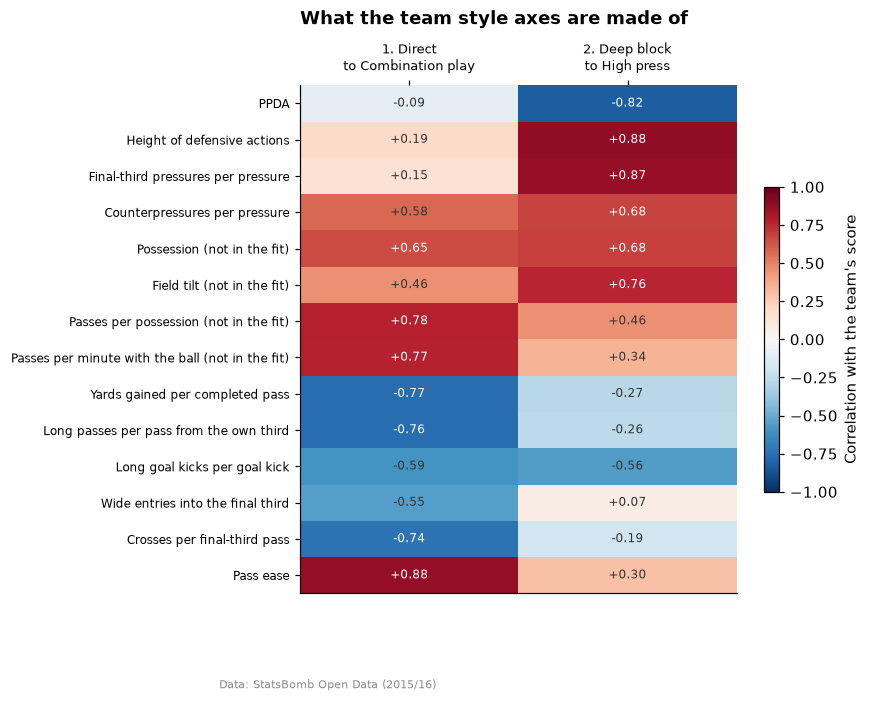

In [7]:
with_axes = pd.DataFrame({a: season.corrwith(scores[a]) for a in scores})[scores.columns]
fig, ax = plt.subplots(figsize=(6.4, 6))
image = ax.imshow(with_axes.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i, n in enumerate(with_axes.index):
    for j, a in enumerate(with_axes.columns):
        value = with_axes.loc[n, a]
        ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) >= 0.6 else "#333333")  # fmt: skip
ax.set_yticks(range(len(with_axes)),
              [NUMBERS[n].split(" (")[0] + ("" if n in kept else " (not in the fit)")
               for n in with_axes.index], fontsize=8)  # fmt: skip
ax.set_xticks(range(n_axes), [f"{a}. {AXIS_NAMES[a][0]}\nto {AXIS_NAMES[a][1]}" for a in scores],
              fontsize=8.5)  # fmt: skip
ax.xaxis.tick_top()
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.6, label="Correlation with the team's score")
ax.set_title("What the team style axes are made of", pad=40)
credit(fig, SOURCE)
plt.show()

### 2.2 The teams on the axes

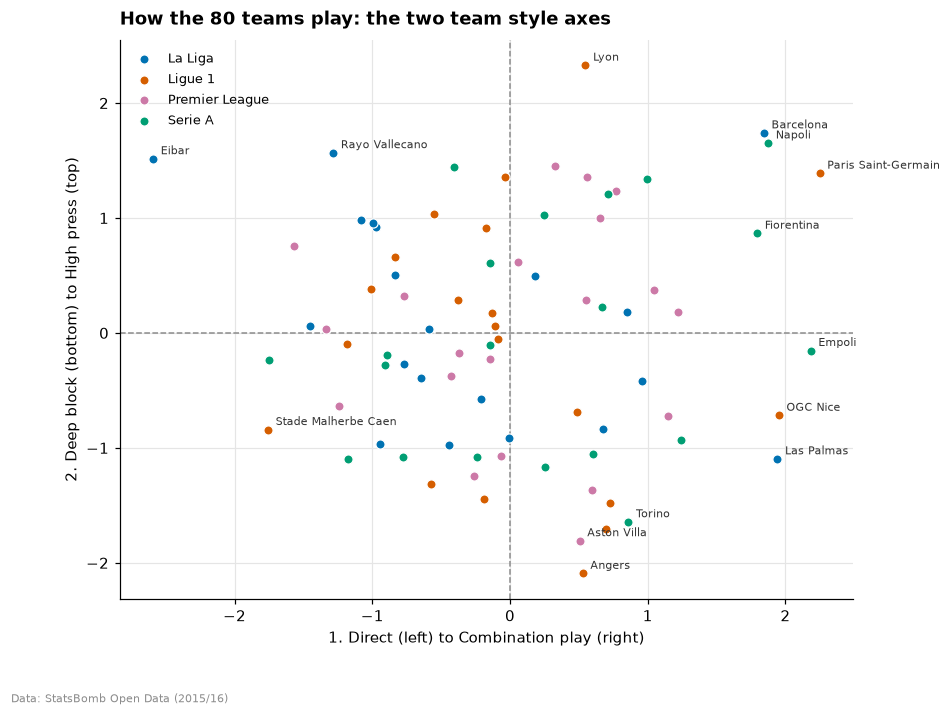

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 6.6))
for name in LEAGUES:
    teams_in = scores.index[league == name]
    ax.scatter(scores.loc[teams_in, 1], scores.loc[teams_in, 2], s=36, label=name,
               color=LEAGUE_COLORS[name], edgecolor="white", linewidth=0.8, zorder=3)  # fmt: skip
for team in scores.pow(2).sum(axis=1).nlargest(14).index:
    ax.annotate(team_names.team_name[team], (scores.loc[team, 1], scores.loc[team, 2]),
                xytext=(5, 3), textcoords="offset points", fontsize=7.5,
                color="#333333")  # fmt: skip
ax.axhline(0, color=GREY, lw=1, ls="--")
ax.axvline(0, color=GREY, lw=1, ls="--")
ax.set_xlabel(f"1. {AXIS_NAMES[1][0]} (left) to {AXIS_NAMES[1][1]} (right)")
ax.set_ylabel(f"2. {AXIS_NAMES[2][0]} (bottom) to {AXIS_NAMES[2][1]} (top)")
ax.set_title("How the 80 teams play: the two team style axes", pad=10)
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(color="#E5E5E5")
credit(fig, SOURCE)
plt.show()
ends = pd.DataFrame({
    (f"{a}. {AXIS_NAMES[a][0]} to {AXIS_NAMES[a][1]}", end): [
        f"{team_names.team_name[t]} ({scores.loc[t, a]:+.1f})"
        for t in (scores[a].nsmallest(5) if end == "Low end" else scores[a].nlargest(5)).index
    ]
    for a in scores for end in ("Low end", "High end")
})  # fmt: skip
display(ends.style.set_caption("The five teams at each end of each axis (scores in standard "
                               "deviations)"))  # fmt: skip

### 2.3 Pass networks

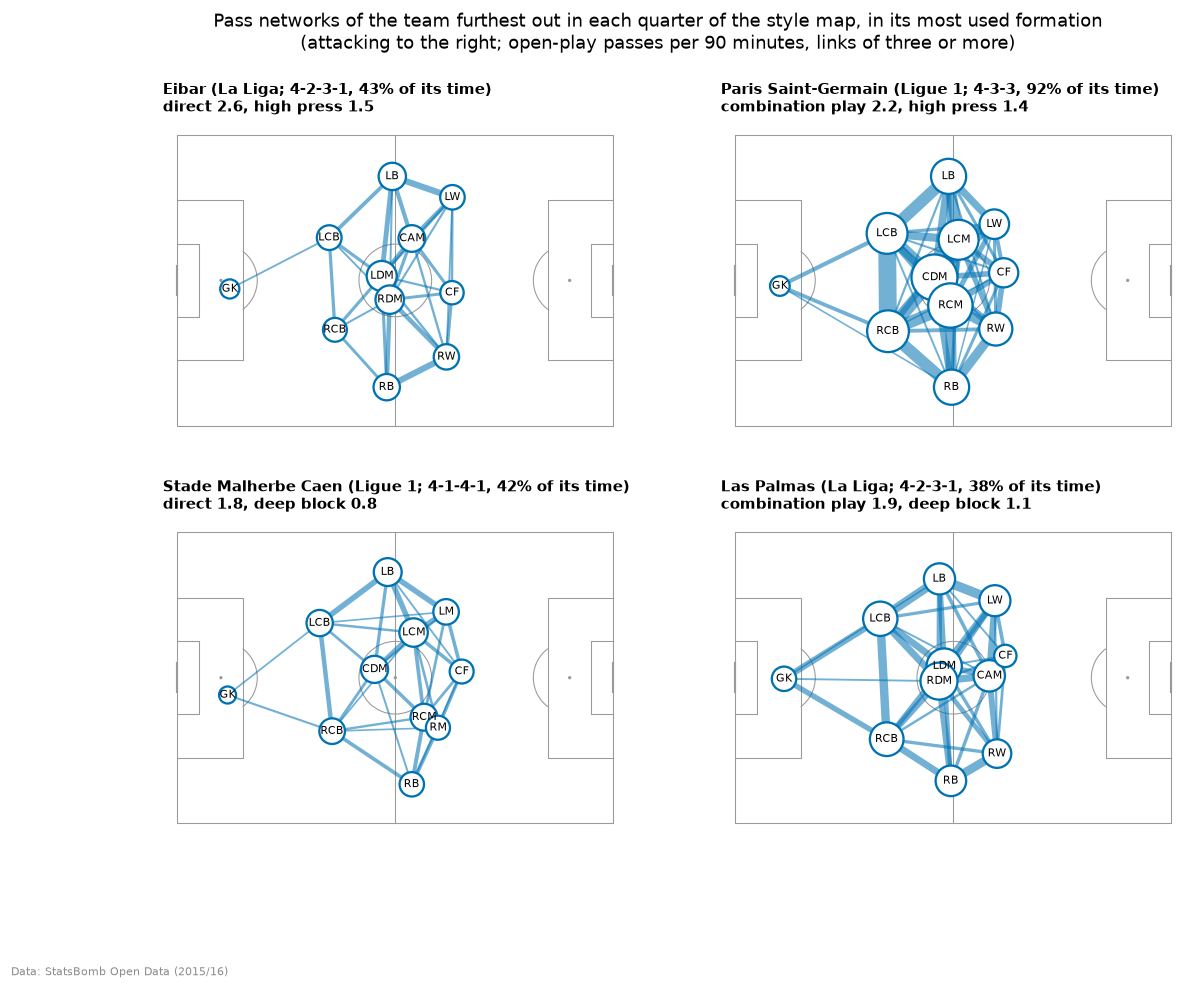

Paris Saint-Germain 703 open-play passes per 90, the most between CDM and RCM (38); Las Palmas 509 open-play passes per 90, the most between LB and LW (19); Eibar 343 open-play passes per 90, the most between LB and LW (12); Stade Malherbe Caen 337 open-play passes per 90, the most between LB and LCB (11).


In [9]:
def described(team):
    """A team's place on the two axes, by the names of the ends it leans to."""
    return ", ".join(
        f"{AXIS_NAMES[a][int(scores.loc[team, a] > 0)].lower()} {abs(scores.loc[team, a]):.1f}"
        for a in (1, 2)
    )


quadrant = list(zip(scores[1] > 0, scores[2] > 0, strict=True))
far = scores.pow(2).sum(axis=1)
corners = [(True, True), (True, False), (False, True), (False, False)]
shown_teams = [far[[q == c for q in quadrant]].idxmax() for c in corners]
pitch = Pitch(pitch_type="statsbomb", line_color="#9A9A9A", linewidth=0.7, line_zorder=1)
fig, axs = plt.subplots(2, 2, figsize=(12, 8.6))
lines = []
for ax, team in zip(axs[[0, 1, 0, 1], [1, 1, 0, 0]], shown_teams, strict=True):
    pitch.draw(ax=ax)
    network = pass_network(con, team)
    top = network.edges.loc[network.edges.passes.idxmax()]
    lines.append(f"{team_names.team_name[team]} {network.nodes.passes.sum():.0f} open-play passes "
                 f"per 90, the most between {position_code(top.a)} and {position_code(top.b)} "
                 f"({top.passes:.0f})")  # fmt: skip
    nodes, edges = network.nodes, network.edges[network.edges.passes >= 3]
    for e in edges.itertuples():
        pitch.lines(nodes.x[e.a], nodes.y[e.a], nodes.x[e.b], nodes.y[e.b], ax=ax,
                    lw=e.passes / 3, color=OKABE_ITO[0], alpha=0.55, zorder=2)  # fmt: skip
    pitch.scatter(nodes.x, nodes.y, s=nodes.passes * 9, ax=ax, color="white",
                  edgecolors=OKABE_ITO[0], linewidth=1.5, zorder=3)  # fmt: skip
    for position, row in nodes.iterrows():
        pitch.annotate(position_code(position), (row.x, row.y), ax=ax, ha="center",
                       va="center", fontsize=7, zorder=4)  # fmt: skip
    ax.set_title(f"{team_names.team_name[team]} ({league[team]}; {network.formation}, "
                 f"{network.share:.0%} of its time)\n{described(team)}", fontsize=9.5)  # fmt: skip
fig.suptitle("Pass networks of the team furthest out in each quarter of the style map, in its "
             "most used formation\n(attacking to the right; open-play passes per 90 minutes, "
             "links of three or more)", y=0.99)  # fmt: skip
credit(fig, SOURCE)
plt.show()
print("; ".join(lines) + ".")

### What section 2 shows

- **Teams differ in two directions.** One component stands well above chance and a second sits
  on the line (an eigenvalue of 1.525, against 1.522 for shuffled data over 200 shuffles and
  1.524 over 10,000). Both axes the rule keeps are reliable over a season (0.95 and 0.85) and
  found again in half the teams (congruence 0.98); together they hold 68% of the ten numbers'
  variation.
- **1. Direct to combination play** (35%): the ease of a team's passes (+0.88) and its
  counterpressing (+0.58), against the yards a pass gains (−0.77), long balls from the back
  (−0.76), crosses (−0.74), long goal kicks (−0.59) and wide entries (−0.55); passes per
  possession and tempo, left out of the fit, go with it (+0.78 and +0.77). Eibar, Caen,
  Frosinone, Crystal Palace and Granada at one end; Paris Saint-Germain, Empoli, Nice, Las Palmas
  and Napoli at the other.
- **2. Deep block to high press** (33%): the height of defensive actions (+0.88), final-third
  pressures (+0.87), PPDA (−0.82) and counterpressing (+0.68); field tilt goes with it (+0.76).
  Angers, Aston Villa, Troyes, Torino and Lorient at one end; Lyon, Barcelona, Napoli, Rayo
  Vallecano and Eibar at the other.
- **Strong teams lean to combination play and a high press, not all of them.** The scores follow
  points per match (Spearman +0.44 and +0.52): Paris Saint-Germain, Barcelona, Napoli and
  Juventus combine and press. But Leicester City, the Premier League champions, play the most
  direct game of the twelve teams with the most points (−1.3) with an average press; Eibar
  presses as high as Napoli from the most direct game of all; Las Palmas and Nice combine from a
  deep block.
- **The pass networks show the two directions.** Paris Saint-Germain's 4-3-3 plays 703 open-play
  passes per 90 minutes, through its centre-backs and midfield three (38 between the defensive and
  the right central midfielder); Eibar's 4-2-3-1 plays 343, the most of them up the left flank,
  full-back to winger. Caen (337) and Las Palmas (509) both defend deep, Caen with long balls, Las
  Palmas passing out from the back.

## 3. Players within teams

How much of a player's style is the team's, and whether that part follows the two team style
axes. Read on the regulars (900 minutes or more in their group's positions, notebook 05) who
played for one team all season: their style descriptors and their scores on their group's style
axes, not shrunk, both as recorded and on an even share of possession (as the search reads them).

- **The team's share**: how much of each descriptor and axis the team explains within the group,
  beyond chance (`leagues.team_effect`, as in notebook 05).
- **The team axes' share**: how much the team's scores on the two team style axes explain
  (adjusted R²). A team's scores are computed without the player's own actions: a centre-back
  plays about a tenth of their team's long balls from the back, and leaving them in would credit
  the team with the player's own style.
- **Which descriptors follow which team axis**: their correlations with the team's scores, against
  1,000 shuffles of the scores among the teams (a team's players keep sharing a score).
- **The players who changed team in January**: the players with 450 minutes or more in their
  group's positions at two teams (notebook 05, section 1.3). Each descriptor and axis at each
  club, on an even share and not shrunk; the change from the first club to the second, in standard
  deviations of the group's regulars, against the change the team axes predict: the slopes of the
  descriptor on the team's two scores among the one-team regulars, times the change in the team's
  scores (each club's without the player). The slope of the change observed on the change
  predicted, through the origin, is 1 if players change as much as the team axes predict and 0 if
  the association between a team's style and its players' is all in who the team picked. Chance
  from 10,000 shuffles of the team changes among the players; an interval from 2,000 resamples of
  the players.

### 3.1 How much of a player's style is the team's

In [10]:
OUTFIELD = list(cfg.roles.descriptors)
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
COLORS = position_colors(cfg)
GROUP_COLORS = {g: COLORS["W" if g == "AMW" else g] for g in OUTFIELD}
group = (
    con.sql("SELECT player_id, comparison_group FROM profile_players")
    .df()
    .set_index("player_id")
    .comparison_group
)
player_names = (
    con.sql("SELECT player_id, player_name FROM profile_players")
    .df()
    .set_index("player_id")
    .player_name
)
style = {
    t: con.sql(f"SELECT * FROM {t}").df()
    for t in ("style_values", "style_descriptors", "style_loadings", "style_recording")
}  # fmt: skip
style_minutes = style["style_values"].groupby("player_id").minutes.first()
regulars = style_minutes.index[style_minutes >= cfg.compared.minutes]
own_season = seasons.own  # each player's own counts at each team, on the teams' scale
team_of = whole_season_team(seasons, regulars)
one_team = team_of.index
team_axes = scores_without(seasons, axes, one_team, team_of.to_numpy())  # without the player
with_player = scores.loc[team_of.to_numpy()].set_index(one_team)
own_part = own_season.loc[list(zip(one_team, team_of, strict=True))].set_index(one_team)
own_part = pd.DataFrame({
    "passes": own_part.passes / season_sums.passes.loc[team_of].to_numpy(),
    "long": own_part.long_passes_own_third
    / season_sums.long_passes_own_third.loc[team_of].to_numpy(),
}).groupby(group.loc[one_team]).median()  # fmt: skip
print(
    f"Regulars who played for one team all season: {len(one_team):,} of {len(regulars):,} ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in group.loc[one_team].value_counts().reindex(OUTFIELD).items())
    + "). A regular's share of their team's open-play passes, median: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {own_part.passes[g]:.1%}" for g in OUTFIELD)
    + f"; of its long balls from the back, centre-backs {own_part.long['CB']:.1%}. The team's "
    "scores without the player correlate "
    + " and ".join(f"{team_axes[a].corr(with_player[a]):.2f}" for a in team_axes)
    + " with the team's own."
)  # fmt: skip

Regulars who played for one team all season: 1,106 of 1,176 (centre-backs 241, full-backs 231, central midfielders 267, attacking midfielders and wingers 229, centre-forwards 138). A regular's share of their team's open-play passes, median: centre-backs 6.1%, full-backs 5.7%, central midfielders 7.4%, attacking midfielders and wingers 4.8%, centre-forwards 3.2%; of its long balls from the back, centre-backs 8.9%. The team's scores without the player correlate 0.99 and 0.97 with the team's own.


In [11]:
VERSIONS = {"As recorded": "recorded", "On an even share": "adjusted"}  # style_values columns
SHUFFLES = 1000


def values_of(g, column):
    """A group's one-team regulars: their descriptors (a `style_values` column) and their scores
    on the group's style axes (columns "axis 1", ...)."""
    t = style["style_values"][style["style_values"].comparison_group == g]
    ids = one_team[(group.loc[one_team] == g).to_numpy()]
    d = t.pivot(index="player_id", columns="descriptor", values=column)
    d = d.loc[ids, list(cfg.roles.descriptors[g])]
    s = axes_of(style["style_descriptors"], style["style_loadings"], g).scores(d)
    return pd.concat([d, s.rename(columns=lambda a: f"axis {a}")], axis=1)


def explained(y, x):
    """Adjusted R² of `y` on the columns of `x`, with an intercept."""
    x1 = np.column_stack([np.ones(len(x)), x])
    residual = y - x1 @ np.linalg.lstsq(x1, y, rcond=None)[0]
    return 1 - (residual @ residual / (len(y) - x1.shape[1])) / y.var(ddof=1)


def standardised(a):
    return (a - a.mean(axis=0)) / a.std(axis=0)


rng = np.random.default_rng(SEED)
shuffled = [rng.permutation(len(scores)) for _ in range(SHUFFLES)]
parts, chance = [], {}
for g in OUTFIELD:
    for version, column in VERSIONS.items():
        v = values_of(g, column)
        t = team_axes.loc[v.index]
        for m in v:
            y = v[m].to_numpy(float)
            frame = pd.DataFrame({"v": y, "team": team_of.loc[v.index].to_numpy(), "group": g})
            parts.append({
                "group": g, "version": version, "value": m, "team": team_effect(frame, "v"),
                "axes": explained(y, t.to_numpy()),
                **{f"r{a}": np.corrcoef(y, t[a])[0, 1] for a in t},
            })  # fmt: skip
    v = values_of(g, "adjusted")
    z = standardised(v.to_numpy(float))
    at_team = scores.index.get_indexer(team_of.loc[v.index])
    null = [np.abs(z.T @ standardised(scores.to_numpy()[order][at_team]) / len(z)).ravel()
            for order in shuffled]  # fmt: skip
    chance[g] = np.quantile(np.concatenate(null), 0.95)
parts = pd.DataFrame(parts)
is_axis = parts.value.str.startswith("axis")
d = parts[~is_axis]
by_group = d.pivot_table(index="group", columns="version", values=["team", "axes"],
                         aggfunc="median").loc[OUTFIELD]  # fmt: skip
even = d[d.version == "On an even share"].set_index(["group", "value"])
captured = (even["axes"].clip(lower=0).groupby(level=0).sum()
            / even.team.clip(lower=0).groupby(level=0).sum())  # fmt: skip
table = pd.DataFrame({
    "Regulars": group.loc[one_team].value_counts().reindex(OUTFIELD),
    "Descriptors": d.groupby("group").value.nunique().reindex(OUTFIELD),
    **{f"Team's share, {v.lower()}": by_group["team", v] for v in VERSIONS},
    **{f"Team axes' share, {v.lower()}": by_group["axes", v] for v in VERSIONS},
    "Of the team's share, the axes'": captured.reindex(OUTFIELD),
    "Chance (|correlation|)": pd.Series(chance),
}).rename(index=GROUP_NAMES)  # fmt: skip
display(
    table.style.format("{:.2f}", subset=table.columns[2:])
    .format("{:.0%}", subset="Of the team's share, the axes'")
    .set_caption("How much of a player's style descriptors the team explains beyond chance, and "
                 "how much its scores on the two team style axes explain (adjusted R²; medians "
                 "over the group's descriptors); the axes' part of the team's (sums over the "
                 "descriptors, on an even share); the 95th percentile of the correlations with "
                 "the team's scores shuffled among the teams")
)  # fmt: skip
style_axes = parts[is_axis & (parts.version == "On an even share")]
style_axes = pd.DataFrame({
    "Team's share": style_axes.team.to_numpy(),
    "Team axes' share": style_axes["axes"].to_numpy(),
    **{f"With {a}. {AXIS_NAMES[a][0]} to {AXIS_NAMES[a][1]}": style_axes[f"r{a}"].to_numpy()
       for a in AXIS_NAMES},
}, index=[
    f"{GROUP_NAMES[g]} {a}. {cfg.roles.names[g][a - 1][0]} to {cfg.roles.names[g][a - 1][1]}"
    for g, a in zip(style_axes.group, style_axes.value.str[-1].astype(int), strict=True)
])  # fmt: skip
display(
    style_axes.style.format("{:.2f}", subset=style_axes.columns[:2])
    .format("{:+.2f}", subset=style_axes.columns[2:])
    .set_caption("The players' style axes (notebook 05), on an even share: what the team and the "
                 "team axes explain, and their correlations with the team's scores")
)  # fmt: skip

,Regulars,Descriptors,"Team's share, as recorded","Team's share, on an even share","Team axes' share, as recorded","Team axes' share, on an even share","Of the team's share, the axes'",Chance (|correlation|)
Centre-backs,241,9,0.25,0.19,0.10,0.05,36%,0.15
Full-backs,231,16,0.26,0.27,0.04,0.02,14%,0.16
Central midfielders,267,21,0.06,0.04,0.03,0.04,63%,0.14
Attacking midfielders and wingers,229,20,0.11,0.10,0.05,0.04,50%,0.14
Centre-forwards,138,19,0.13,0.14,0.03,0.01,24%,0.18


,Team's share,Team axes' share,With 1. Direct to Combination play,With 2. Deep block to High press
Centre-backs 1. Short passer to Long passer,0.10,0.07,-0.24,-0.15
Centre-backs 2. Ball-carrier to Direct passer,0.43,0.21,-0.47,+0.03
Centre-backs 3. Central to Wide,0.04,0.03,-0.17,-0.10
Full-backs 1. Dribbler to Box defender,0.20,-0.01,-0.01,+0.03
Full-backs 2. Holds position to Gets into the box,0.50,0.04,-0.19,-0.08
Full-backs 3. Short passer and presser to Long passer,0.22,0.11,-0.31,-0.15
Central midfielders 1. Deep pivot to Advanced midfielder,-0.01,0.02,-0.13,-0.11
Central midfielders 2. Short passer and presser to Long passer,0.16,0.16,-0.35,-0.22
Central midfielders 3. Ground passer to Aerial presence,-0.07,0.02,-0.08,-0.13
Central midfielders 4. Ball-carrier to Forward passer,0.26,0.14,-0.37,+0.11


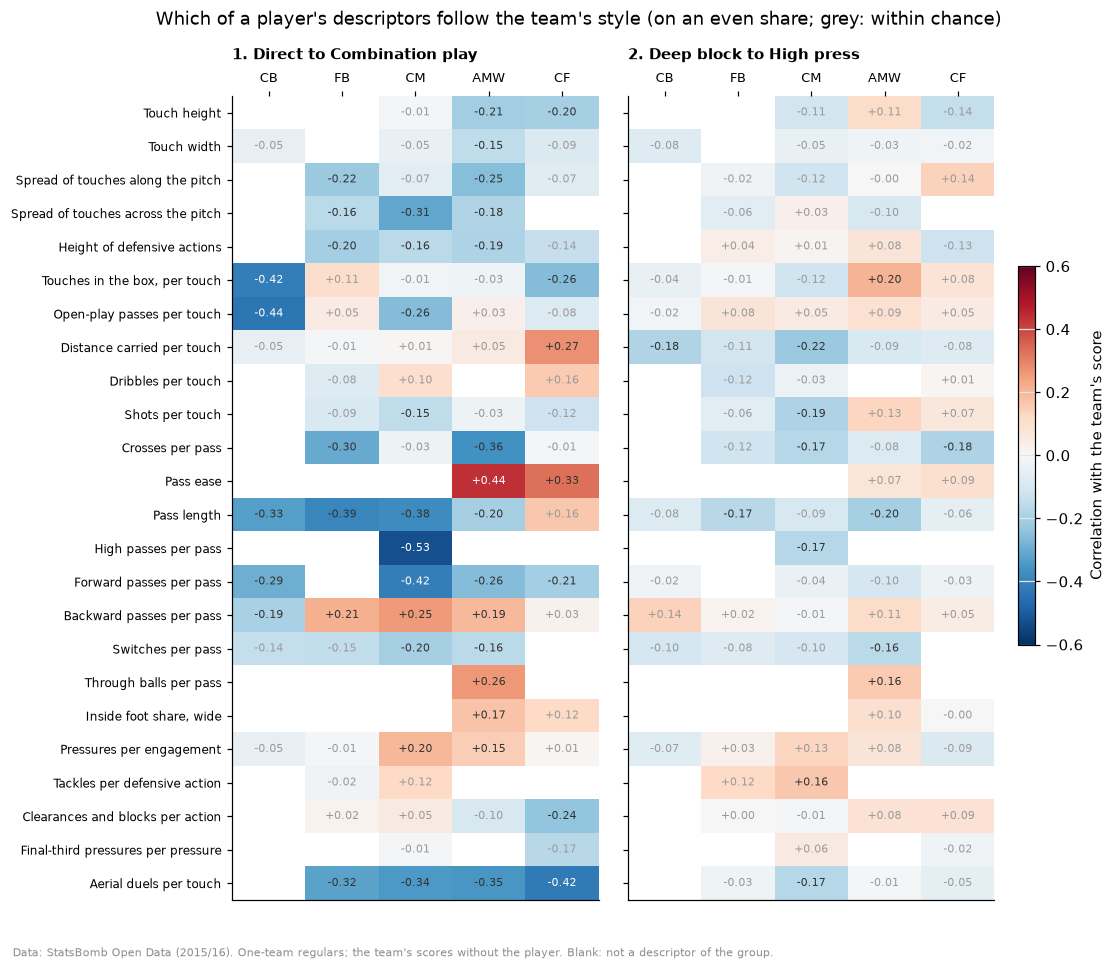

The height of a player's defensive actions (not a centre-back descriptor) follows the team's press as recorded and not on an even share (correlation with axis 2): full-backs +0.40 → +0.04, central midfielders +0.34 → +0.01, attacking midfielders and wingers +0.38 → +0.08, centre-forwards +0.15 → -0.13. The team's possession goes with both axes (Spearman +0.61 and +0.67).


In [12]:
even_parts = d[d.version == "On an even share"]
shown = [m for m in NAMES if m in set(even_parts.value)]
fig, axs = plt.subplots(1, 2, figsize=(10.5, 8.6), sharey=True)
fig.subplots_adjust(left=0.2, right=0.86, top=0.88, bottom=0.03, wspace=0.08)
for ax, a in zip(axs, AXIS_NAMES, strict=True):
    grid = even_parts.pivot(index="value", columns="group", values=f"r{a}").reindex(
        index=shown, columns=OUTFIELD
    )
    image = ax.imshow(grid.to_numpy(), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    for i, m in enumerate(shown):
        for j, g in enumerate(OUTFIELD):
            r = grid.loc[m, g]
            if np.isnan(r):
                continue
            color = ("white" if abs(r) >= 0.4 else "#333333") if abs(r) >= chance[g] else "#9A9A9A"
            ax.text(j, i, f"{r:+.2f}", ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(range(len(OUTFIELD)), OUTFIELD, fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_title(f"{a}. {AXIS_NAMES[a][0]} to {AXIS_NAMES[a][1]}", fontsize=10, pad=24)
    ax.grid(False)
axs[0].set_yticks(range(len(shown)), [LABELS[m].split(" (")[0] for m in shown], fontsize=8)
cax = fig.add_axes([0.88, 0.3, 0.015, 0.4])
fig.colorbar(image, cax=cax, label="Correlation with the team's score")
fig.suptitle("Which of a player's descriptors follow the team's style (on an even share; grey: "
             "within chance)", y=0.97)  # fmt: skip
credit(fig, SOURCE + ". One-team regulars; the team's scores without the player. Blank: not a "
            "descriptor of the group.")  # fmt: skip
plt.show()
heights = d[d.value == "defence_height"].pivot(index="group", columns="version", values="r2")
possession = season.possession.loc[scores.index]
print(
    "The height of a player's defensive actions (not a centre-back descriptor) follows the "
    "team's press as recorded and not on an even share (correlation with axis 2): "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {heights.at[g, 'As recorded']:+.2f} → "
                f"{heights.at[g, 'On an even share']:+.2f}"
                for g in OUTFIELD if g in heights.index)
    + ". The team's possession goes with both axes (Spearman "
    + " and ".join(f"{possession.corr(scores[a], method='spearman'):+.2f}" for a in scores)
    + ")."
)  # fmt: skip

### 3.2 The players who changed team in January

In [13]:
MOVER_MINUTES = 450  # in the group's positions at each club, as in notebooks 05 and 06
STYLE_SUMS = [*SUMMED, "minutes", *POSSESSION]
rows = style_matches(con, cfg, group)  # the matches in the group's positions
rows = rescale_players(rows, group, recording_context(rows, cfg), style["style_recording"])
stints = rows.groupby(["player_id", "team_id"]).agg(minutes=("minutes", "sum"),
                                                    first=("match_date", "min"))  # fmt: skip
stints = stints[stints.minutes >= MOVER_MINUTES].reset_index().sort_values(["player_id", "first"])
clubs = stints[stints.player_id.map(stints.player_id.value_counts()) >= 2].copy()
assert clubs.player_id.value_counts().max() == 2
clubs["club"] = clubs.groupby("player_id").cumcount()
movers = pd.Index(clubs.player_id.unique())
at_club = (
    rows.merge(clubs[["player_id", "team_id", "club"]], on=["player_id", "team_id"])
    .groupby(["player_id", "club"])[STYLE_SUMS].sum()
)  # fmt: skip
club_team = clubs.set_index(["player_id", "club"]).team_id.unstack().loc[movers]
team_change = scores_without(seasons, axes, movers, club_team[1].to_numpy()) - scores_without(
    seasons, axes, movers, club_team[0].to_numpy()
)
not_shrunk = style["style_descriptors"].assign(k=0.0)  # `place` without the pull to the mean
pairs, coefficients = [], []
for g in OUTFIELD:
    ids = movers[(group.loc[movers] == g).to_numpy()]
    v = values_of(g, "adjusted")
    slopes = style_slopes(v, team_axes.loc[v.index]) / v.std()
    group_axes = axes_of(style["style_descriptors"], style["style_loadings"], g)
    at = []
    for c in (0, 1):
        values = place(at_club.xs(c, level="club").loc[ids], g, not_shrunk)
        scored = group_axes.scores(values).rename(columns=lambda a: f"axis {a}")
        at.append(pd.concat([values, scored], axis=1))
    observed = (at[1] - at[0]) / v.std()
    pairs.append(pd.DataFrame({
        "group": g, "player_id": np.repeat(ids, v.shape[1]), "value": np.tile(v.columns, len(ids)),
        "observed": observed.to_numpy().ravel(),
        **{f"b{a}": np.tile(slopes.loc[a].to_numpy(), len(ids)) for a in team_axes},
    }))  # fmt: skip
pairs = pd.concat(pairs, ignore_index=True)
mover_at = movers.get_indexer(pairs.player_id)
b = pairs[[f"b{a}" for a in team_axes]].to_numpy()
pairs["predicted"] = (b * team_change.to_numpy()[mover_at]).sum(axis=1)
pairs["kind"] = np.where(pairs.value.str.startswith("axis"), "Style axes", "Descriptors")


def slope(predicted, observed, weight=1.0):
    """Least-squares slope through the origin."""
    return (weight * predicted * observed).sum() / (weight * predicted**2).sum()


rng = np.random.default_rng(SEED)
orders = [rng.permutation(len(movers)) for _ in range(10_000)]
resamples = [np.bincount(rng.integers(0, len(movers), len(movers)), minlength=len(movers))
             for _ in range(2000)]  # fmt: skip
moved, shuffled_slopes = {}, {}
for kind, p in pairs.groupby("kind", sort=False):
    at, bk, o = mover_at[p.index], b[p.index], p.observed.to_numpy()
    shuffled_slopes[kind] = np.array(
        [slope((bk * team_change.to_numpy()[order][at]).sum(axis=1), o) for order in orders]
    )
    boot = [slope(p.predicted.to_numpy(), o, w[at]) for w in resamples]
    point = slope(p.predicted.to_numpy(), o)
    dropped = [slope(p.predicted[at != i], p.observed[at != i]) for i in range(len(movers))]
    moved[kind] = {
        "Pairs": len(p), "Slope": point,
        "95% interval": f"{np.quantile(boot, 0.025):.2f} to {np.quantile(boot, 0.975):.2f}",
        "Chance (95% of shuffles)": np.quantile(shuffled_slopes[kind], 0.95),
        "Shuffles at or above": (shuffled_slopes[kind] >= point).mean(),
        "Correlation": np.corrcoef(p.predicted, o)[0, 1],
        "One player left out": f"{min(dropped):.2f} to {max(dropped):.2f}",
    }  # fmt: skip
moved = pd.DataFrame(moved).T
display(
    moved.style.format({"Slope": "{:.2f}", "Chance (95% of shuffles)": "{:.2f}",
                        "Shuffles at or above": lambda s: f"{s:.4f}" if s else "under 0.0001",
                        "Correlation": "{:.2f}"})
    .set_caption(f"{len(movers)} players who changed team in January: the change in their style "
                 "against the change the team axes predict (slope through the origin; 1: as "
                 "predicted, 0: no change)")
)  # fmt: skip
names_of = con.sql("SELECT DISTINCT team_id, team_name FROM teams").df().set_index("team_id")
largest = team_change.pow(2).sum(axis=1).nlargest(3).index
minutes_at = at_club.minutes.unstack()
print(
    f"{len(movers)} players ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in group.loc[movers].value_counts().reindex(OUTFIELD).dropna().items())
    + f"), a median {minutes_at[0].median():,.0f} minutes in their group's positions at the first "
    f"club and {minutes_at[1].median():,.0f} at the second. The team change, in standard "
    "deviations: a median "
    + " and ".join(f"{team_change[a].abs().median():.1f}" for a in team_change)
    + " on the two axes. The largest: "
    + "; ".join(
        f"{player_names[p]}, {names_of.team_name[club_team.at[p, 0]]} to "
        f"{names_of.team_name[club_team.at[p, 1]]} ("
        + ", ".join(f"{AXIS_NAMES[a][int(team_change.at[p, a] > 0)].lower()} "
                    f"{abs(team_change.at[p, a]):.1f}" for a in team_change)
        + ")"
        for p in largest
    )
    + "."
)  # fmt: skip

,Pairs,Slope,95% interval,Chance (95% of shuffles),Shuffles at or above,Correlation,One player left out
Descriptors,389,1.00,0.46 to 1.44,0.45,under 0.0001,0.28,0.88 to 1.14
Style axes,77,1.02,0.47 to 1.69,0.61,0.0021,0.37,0.89 to 1.17


22 players (centre-backs 4, full-backs 2, central midfielders 6, attacking midfielders and wingers 5, centre-forwards 5), a median 945 minutes in their group's positions at the first club and 869 at the second. The team change, in standard deviations: a median 0.7 and 0.9 on the two axes. The largest: Modibo Diakité, Frosinone to Sampdoria (combination play 3.1, deep block 0.8); Steven Fletcher, Sunderland to Olympique de Marseille (combination play 0.2, high press 2.7); Mario Suárez Mata, Fiorentina to Watford (direct 2.2, deep block 1.1).


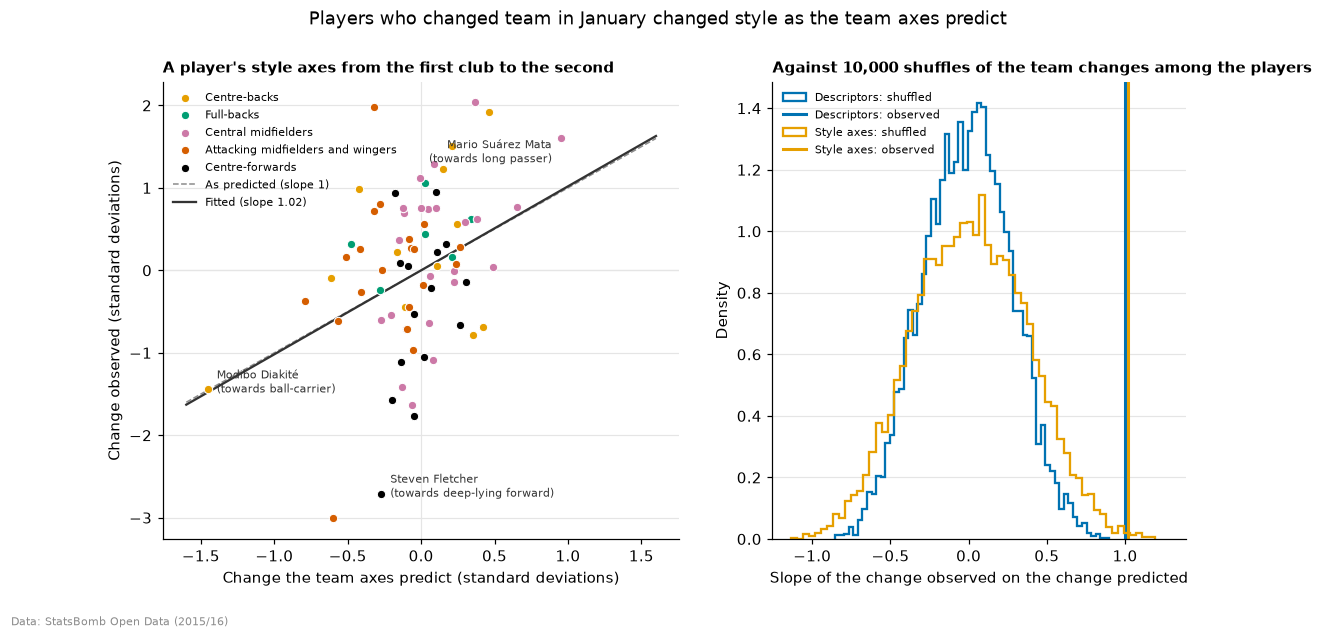

In [14]:
p = pairs[pairs.kind == "Style axes"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.25, 1]})
for g in OUTFIELD:
    q = p[p.group == g]
    if len(q):
        ax.scatter(q.predicted, q.observed, s=30, color=GROUP_COLORS[g], label=GROUP_NAMES[g],
                   edgecolor="white", linewidth=0.7, zorder=3)  # fmt: skip
reach = np.abs(p.predicted).max() * 1.1
line = np.array([-reach, reach])
ax.plot(line, line, color=GREY, lw=1, ls="--", label="As predicted (slope 1)")
ax.plot(line, moved.at["Style axes", "Slope"] * line, color="#333333", lw=1.5,
        label=f"Fitted (slope {moved.at['Style axes', 'Slope']:.2f})")  # fmt: skip
for player in largest:  # each at their axis with the largest predicted change
    q = p[p.player_id == player]
    top = q.loc[q.predicted.abs().idxmax()]
    end = cfg.roles.names[top.group][int(top.value[-1]) - 1][int(top.observed > 0)]
    right = top.predicted > 0
    ax.annotate(f"{player_names[player]}\n(towards {end.lower()})", (top.predicted, top.observed),
                xytext=(-6, -16) if right else (6, -2), textcoords="offset points",
                ha="right" if right else "left", fontsize=7.5, color="#333333")  # fmt: skip
ax.axhline(0, color="#E5E5E5", lw=0.8, zorder=0)
ax.axvline(0, color="#E5E5E5", lw=0.8, zorder=0)
ax.set_xlabel("Change the team axes predict (standard deviations)")
ax.set_ylabel("Change observed (standard deviations)")
ax.set_title("A player's style axes from the first club to the second", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left")
for i, kind in enumerate(moved.index):
    ax2.hist(shuffled_slopes[kind], bins=60, histtype="step", color=OKABE_ITO[i], lw=1.5,
             density=True, label=f"{kind}: shuffled")  # fmt: skip
    ax2.axvline(moved.at[kind, "Slope"], color=OKABE_ITO[i], lw=2,
                label=f"{kind}: observed")  # fmt: skip
ax2.set_xlim(right=max(moved.Slope.max(), *(s.max() for s in shuffled_slopes.values())) + 0.2)
ax2.set_xlabel("Slope of the change observed on the change predicted")
ax2.set_ylabel("Density")
ax2.set_title("Against 10,000 shuffles of the team changes among the players", fontsize=10)
ax2.legend(fontsize=7.5, loc="upper left")
fig.suptitle("Players who changed team in January changed style as the team axes predict", y=1.0)
credit(fig, SOURCE)
plt.show()

### What section 3 shows

- **Part of a player's style is the team's, and the two team axes hold only some of that part.**
  On an even share of possession the team explains a median 0.04 (central midfielders) to 0.27
  (full-backs) of a descriptor's variation beyond chance; its scores on the team axes explain 0.01
  to 0.05, between 14% (full-backs) and 63% (central midfielders) of the team's part. The rest is
  a team's own: its formation and what it asks of each position. Full-backs show it most: the team
  explains half of how far forward they get (style axis 2, 0.50), the team axes 0.04 of it.
- **What follows a team's style is how the ball is moved.** At direct teams players of every group
  play longer passes (pass length −0.33 to −0.39 among defenders and central midfielders), go up
  for more aerial duels (−0.32 to −0.42) and cross more (full-backs −0.30, attacking midfielders
  and wingers −0.36); central midfielders play more high passes (−0.53) and more forward passes
  (−0.42); at teams that combine, attacking players' passes are easier (+0.44 and +0.33). On the
  players' own style axes: centre-backs lean to ball-carrying (−0.47 with direct to combination
  play), central midfielders to short passing and carrying (−0.35 and −0.37).
- **The press does not show on an even share.** No descriptor follows the deep block to high
  press axis by more than 0.22. As recorded, the height of a player's defensive actions does
  follow it (+0.34 to +0.40, centre-forwards +0.15); on an even share it does not (−0.13 to +0.08).
  Possession goes with the press (Spearman +0.67 across the teams), so putting a player on an even
  share of possession also takes out the height the team's press gives them.
- **Players who changed team in January changed style as the team axes predict.** Over 22 players
  the slope of the change observed on the change predicted is 1.00 (0.46 to 1.44) over their
  descriptors and 1.02 (0.47 to 1.69) over their style axes, against 0.45 and 0.61 for the 95th
  percentile of shuffled team changes; leaving any one player out keeps it between 0.88 and 1.17.
  Mario Suárez went from Fiorentina to Watford, 2.2 standard deviations more direct, and became a
  longer passer; Modibo Diakité went from Frosinone, the third most direct team, to Sampdoria (3.1
  towards combination play) and carried the ball more. The link between a team's style and its
  players' is the team's doing more than its choice of players: a player who joins a more direct
  team plays more directly. With 22 players the interval is wide, and the predicted changes are
  small against the noise of half a season (correlations of 0.28 and 0.37).
- **Taking the player out of the team's numbers changes little.** A regular plays a median 3% to
  7% of their team's open-play passes (centre-backs 9% of its long balls from the back); the
  team's scores without them correlate 0.99 and 0.97 with the team's own.

## 4. Fit

Whether a signing plays more at a club whose players in their position play like them. Read on
the profiled players who changed club for 2016/17, to another of the 80 teams still in the same
league.

- **The signings.** A player's club in the first half of 2016/17 (July to December) is the club
  they played the most minutes for in it, over every competition in Transfermarkt's appearances;
  for a player without appearances in it, the club their last transfer of the summer went to
  (`outcomes.first_half_clubs`). A signing is a player whose club then is not the last team they
  played for in 2015/16.
- **A club's style in a position.** The matches all the club's players of the comparison group
  played in the group's positions in 2015/16, summed, and the style descriptors read from the
  sums on the season's terms (on an even share of possession, pulled towards the group's mean as
  a player's are, which a club's minutes leave nearly where they are); the player's own matches
  left out.
- **Fit.** The distance between the player's descriptors (shrunk, as the search reads them) and
  the club's, in the search's descriptor block (notebook 06), after the change the team axes
  predict (section 3: each descriptor's slopes on the team's two scores, times the change in the
  team's scores from the old club without the player to the new club). It is read as a rank
  (`teams.fit`): the share of the other clubs (all but the old and the new) the player is
  further from than from the new club; 1 if the new club is the one the player fits best, 0.5 if
  it fits them as well as an average club. The rank takes out how typical a player is: a player
  near the group's mean is near every club. As a check of the measure, the one-team regulars of
  section 3 against their own club without them.
- **The outcome**: the share of the new club's league minutes the player played in 2016/17 (their
  league minutes over the club's league matches times 90; 0 if none; `outcomes.league_share`).
- **The model**: least squares of the share on fit, with the player's value against the new
  club's (the log of their value on 30 June 2016 less the log of the median value of the club's
  2015/16 regulars, 900 minutes or more), age and its square, 2015/16 minutes and the comparison
  group. The slope is the share of minutes gained from the club the player fits worst to the one
  they fit best. An interval from 2,000 resamples of the new clubs (a club's signings together);
  chance from 10,000 shuffles of the new clubs among a group's signings (each player's fit read
  against another signing's club).
- **The coach.** A club's style is read from 2015/16, and a new coach may change it. The model is
  fitted again with one slope for the clubs whose coach in the first league match of 2016/17 was
  the coach of the last match of 2015/16 and one for the others (`outcomes.coaches`). This split
  was added during the analysis, once Transfermarkt's games turned out to name each match's coach;
  the test set out beforehand is the one over all signings, and both are reported.
- **Checks**: fit without the predicted change; fit as recorded (keeping the height the team's
  press gives a player, which the even share takes out; section 3); and the step in team
  strength (the new club's points per match less the old club's) as a further control, since a
  player who moves to a much stronger team finds both another style and more competition.

### 4.1 The signings and the measure

In [15]:
SEASON = 2016  # 2016/17, the season after the market view
POOL = [c.competition_id for c in cfg.statsbomb.competitions if c.scouting_pool]
team_map = con.sql("SELECT team_id, club_id, competition_id FROM team_map").df()
club_of = team_map[team_map.competition_id.isin(POOL)].set_index("team_id").club_id
team_of_club = pd.Series(club_of.index, index=club_of.to_numpy())
leagues = club_leagues(con).pivot(index="club_id", columns="season", values="league")
staying = club_of.index[
    (club_of.map(leagues[SEASON]) == club_of.map(leagues[SEASON - 1])).to_numpy()
]
last_team = (
    con.sql(
        "SELECT player_id, arg_max(team_id, match_date) AS team_id FROM player_matches "
        "JOIN matches USING (match_id) WHERE scouting_pool AND played GROUP BY player_id"
    )
    .df()
    .set_index("player_id")
    .team_id
)
first_half = first_half_clubs(con, SEASON).set_index("player_id").reindex(group.index)
signings = pd.DataFrame({"group": group, "old": last_team.loc[group.index],
                         "club_id": first_half.club_id, "source": first_half.source})  # fmt: skip
signings["new"] = signings.club_id.map(team_of_club)
signings = signings[signings.new.isin(staying) & (signings.new != signings.old)].copy()
signings["new"] = signings.new.astype(int)

values_table = style["style_values"]
known = values_table.recorded.notna()
by_descriptor = [values_table.comparison_group, values_table.descriptor]
recorded_mean = (values_table.recorded * values_table.minutes).where(known).groupby(
    by_descriptor
).sum() / values_table.minutes.where(known).groupby(
    by_descriptor
).sum()  # weighted by minutes, as `profiles.shrink` weighs the group's mean


def on_terms(sums, g, version):
    """Group g's descriptors from sums of matches in its positions, on the season's terms: on an
    even share of possession ("adjusted", `roles.place`) or as recorded ("recorded"), pulled
    towards the group's mean with the season's K."""
    if version == "adjusted":
        return place(sums, g, style["style_descriptors"])
    d = style["style_descriptors"]
    k = d[d.comparison_group == g].set_index("descriptor").k
    return towards(descriptors(sums)[list(cfg.roles.descriptors[g])], sums.minutes,
                   recorded_mean.loc[g], k)  # fmt: skip


VARIANTS = {  # name: (descriptors, after the change the team axes predict)
    "On an even share, at the new club's style": ("adjusted", True),
    "On an even share, as the player played": ("adjusted", False),
    "As recorded, at the new club's style": ("recorded", True),
}
in_group = rows.player_id.map(group)
distances, own_club = {name: [] for name in VARIANTS}, []
for g in OUTFIELD:
    r = rows.loc[in_group == g, ["team_id", "player_id", *STYLE_SUMS]]
    by_player = r.drop(columns="team_id").groupby("player_id").sum()
    ids = signings.index[signings.group == g]
    old_scores = scores_without(seasons, axes, ids, signings.old.loc[ids].to_numpy())
    for version in ("adjusted", "recorded"):
        season_values = on_terms(by_player, g, version)
        if version == "adjusted":  # the season's descriptors, as stored
            stored = values_table[values_table.comparison_group == g].pivot(
                index="player_id", columns="descriptor", values="shrunk"
            )
            assert np.allclose(
                season_values, stored.loc[season_values.index, season_values.columns]
            )
        block = fit_block(season_values[season_values.index.isin(regulars)])
        v = values_of(g, version)[season_values.columns]  # one-team regulars, not shrunk
        shift = {"slopes": style_slopes(v, team_axes.loc[v.index]), "team_scores": scores,
                 "old_scores": old_scores}  # fmt: skip
        placed = partial(on_terms, g=g, version=version)
        for name, (variant, shifted) in VARIANTS.items():
            if variant == version:
                dist = fit_distances(r, placed, block, ids, **(shift if shifted else {}))
                distances[name].append(dist)
        if version == "adjusted":  # the check: one-team regulars against their own club
            reg = one_team[(group.loc[one_team] == g).to_numpy()]
            dist = fit_distances(r, placed, block, reg)
            own_club.append(fit(dist, team_of.loc[reg], team_of.loc[reg]))
distances = {name: pd.concat(parts).loc[signings.index] for name, parts in distances.items()}
fits = pd.DataFrame({name: fit(d, signings.new, signings.old) for name, d in distances.items()})
own_club = pd.concat(own_club)
no_players = fits.index[fits.isna().any(axis=1)]  # new clubs with no players of their group
left_out = signings.loc[no_players]
signings, fits = signings.drop(no_players), fits.drop(no_players)
FIT = next(iter(VARIANTS))  # the measure; the others are checks

rng = np.random.default_rng(SEED)
new_clubs = signings.new.unique()
club_draws = [np.bincount(rng.integers(0, len(new_clubs), len(new_clubs)),
                          minlength=len(new_clubs)) for _ in range(2000)]  # fmt: skip
club_at = pd.Index(new_clubs).get_indexer(signings.new)
mean_fit = [np.average(fits[FIT], weights=w[club_at]) for w in club_draws]
own_by_group = own_club.groupby(group.loc[own_club.index].to_numpy()).mean()
print(
    f"{len(signings)} signings to {len(new_clubs)} of the {len(staying)} clubs still in their "
    "league ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}"
                for g, n in signings.group.value_counts().reindex(OUTFIELD).items())
    + f"); {(signings.source == 'appearances').sum()} from their appearances, "
    f"{(signings.source == 'transfer').sum()} from a summer transfer. Left out, as their new "
    "club played no player of their group in 2015/16: "
    + ", ".join(f"{player_names[p]} ({GROUP_NAMES[left_out.group[p]].lower()}, to "
                f"{team_names.team_name[left_out.new[p]]})" for p in left_out.index)
    + ". The signings' fit to their "
    f"new club: a mean {fits[FIT].mean():.2f} ({np.quantile(mean_fit, 0.025):.2f} to "
    f"{np.quantile(mean_fit, 0.975):.2f}; an average club 0.50). The check: one-team regulars "
    f"against their own club without them, a mean {own_club.mean():.2f} ("
    + ", ".join(f"{GROUP_NAMES[g].lower()} {own_by_group[g]:.2f}" for g in OUTFIELD)
    + ")."
)  # fmt: skip

204 signings to 64 of the 68 clubs still in their league (centre-backs 37, full-backs 38, central midfielders 44, attacking midfielders and wingers 52, centre-forwards 33); 200 from their appearances, 4 from a summer transfer. Left out, as their new club played no player of their group in 2015/16: Adem Ljajić (attacking midfielders and wingers, to Torino), Iago Falqué Silva (attacking midfielders and wingers, to Torino). The signings' fit to their new club: a mean 0.50 (0.46 to 0.55; an average club 0.50). The check: one-team regulars against their own club without them, a mean 0.63 (centre-backs 0.67, full-backs 0.68, central midfielders 0.56, attacking midfielders and wingers 0.61, centre-forwards 0.61).


### 4.2 Fit and minutes

In [16]:
signings["share"] = league_share(con, SEASON, signings.reset_index()).to_numpy()
value = value_at(pool_valuations(con), cfg.backtest.market_view).value
team_minutes = con.sql(
    "SELECT team_id, player_id, sum(minutes_played) AS minutes FROM player_matches "
    "JOIN matches USING (match_id) WHERE scouting_pool GROUP BY ALL"
).df()
club_regulars = team_minutes[team_minutes.minutes >= cfg.compared.minutes]
club_value = club_regulars.player_id.map(value).groupby(club_regulars.team_id).median()
profiled = (
    con.sql("SELECT player_id, age, minutes FROM profile_players").df().set_index("player_id")
)
signings["relative_value"] = np.log(signings.index.map(value).to_numpy()) - np.log(
    signings.new.map(club_value)
)
signings[["age", "minutes"]] = profiled.loc[signings.index, ["age", "minutes"]]
coach = coaches(con, SEASON)
signings["same_coach"] = (signings.club_id.map(coach.before)
                          == signings.club_id.map(coach.after))  # fmt: skip
assert signings[["share", "relative_value", "age"]].notna().all().all()

y = signings.share.to_numpy()
same = signings.same_coach.to_numpy(float)
controls = np.column_stack([
    signings.relative_value, signings.age, (signings.age - signings.age.mean()) ** 2,
    signings.minutes / 1000, pd.get_dummies(signings.group, drop_first=True, dtype=float),
])  # fmt: skip
SLOPES = ["All signings", "Same coach", "New coach", "Same coach less new coach"]


def fit_slopes(f, weight=None, more=controls):
    """The fit slopes (`SLOPES`) for fit values f: least squares of the share of minutes on fit
    and the controls (`more`), then with one slope for each coach status (and the new coach's own
    intercept); rows weighted by `weight` (a resample's counts)."""
    w = np.ones(len(f)) if weight is None else np.sqrt(weight)
    out = []
    for x in (np.column_stack([f, more]),
              np.column_stack([f * same, f * (1 - same), 1 - same, more])):  # fmt: skip
        a = np.column_stack([np.ones(len(f)), x]) * w[:, None]
        out.append(np.linalg.lstsq(a, y * w, rcond=None)[0])
    return np.array([out[0][1], out[1][1], out[1][2], out[1][1] - out[1][2]]), out[0]


club_at = pd.Index(new_clubs).get_indexer(signings.new)
club_draws = [w[club_at] for w in club_draws]
in_groups = [np.flatnonzero((signings.group == g).to_numpy()) for g in OUTFIELD]
shuffles = []
for _ in range(10_000):
    order = np.arange(len(signings))
    for at in in_groups:
        order[at] = rng.permutation(at)
    shuffles.append(order)
results, chance_slopes = {}, {}
for name, d in distances.items():
    d = d.loc[signings.index]
    point, coefficients = fit_slopes(fits[name].to_numpy())
    boot = np.array([fit_slopes(fits[name].to_numpy(), w)[0] for w in club_draws])
    null = np.array([
        fit_slopes(fit(d, signings.new.iloc[order].set_axis(d.index), signings.old).to_numpy())[0]
        for order in shuffles
    ])  # fmt: skip
    chance_slopes[name] = null
    results[name] = pd.DataFrame({
        "Signings": [len(signings), int(same.sum()), int((1 - same).sum()), np.nan],
        "Slope": point,
        "95% interval": [f"{lo:+.2f} to {hi:+.2f}"
                         for lo, hi in np.quantile(boot, [0.025, 0.975], axis=0).T],
        "Chance (95% of shuffles)": np.quantile(null, 0.95, axis=0),
        "Shuffles at or above": (null >= point).mean(axis=0),
    }, index=SLOPES)  # fmt: skip
    if name == FIT:
        value_slope = coefficients[2]  # the relative value's, in the model without coach
display(
    results[FIT].style.format({"Signings": lambda n: "" if np.isnan(n) else f"{n:.0f}",
                               "Slope": "{:+.2f}", "Chance (95% of shuffles)": "{:+.2f}",
                               "Shuffles at or above": "{:.4f}"})
    .set_caption(f"{len(signings)} signings for 2016/17: the share of the new club's league "
                 "minutes gained from the club a player fits worst to the one they fit best "
                 "(least squares with their value against the club's regulars, age, 2015/16 "
                 "minutes and group)")
)  # fmt: skip
step = points.loc[signings.new].to_numpy() - points.loc[signings.old].to_numpy()
with_step = np.column_stack([controls, step])
boot = np.array([fit_slopes(fits[FIT].to_numpy(), w, with_step)[0] for w in club_draws])
STEP = "On an even share, at the new club's style; the step in team strength as a control"
results[STEP] = pd.DataFrame({
    "Slope": fit_slopes(fits[FIT].to_numpy(), more=with_step)[0],
    "95% interval": [f"{lo:+.2f} to {hi:+.2f}"
                     for lo, hi in np.quantile(boot, [0.025, 0.975], axis=0).T],
}, index=SLOPES)  # fmt: skip
checks = pd.DataFrame({
    s: [f"{r.at[s, 'Slope']:+.2f} ({r.at[s, '95% interval']})" for r in results.values()]
    for s in SLOPES
}, index=list(results))  # fmt: skip
display(checks.style.set_caption("The fit slopes (95% intervals) under each check: how fit is "
                                 "measured, and the new club's points per match less the old "
                                 "club's as a further control"))  # fmt: skip
coach_clubs = signings.drop_duplicates("new").same_coach
print(
    f"Signings played a mean {signings.share.mean():.0%} of their new club's league minutes "
    f"({(signings.share == 0).sum()} none). {coach_clubs.sum()} of the {len(coach_clubs)} clubs "
    "kept their coach from the end of 2015/16 into 2016/17. A player valued at twice the median "
    f"of the club's regulars played {value_slope * np.log(2):+.0%} of its minutes, all else equal. "
    f"The step in team strength and fit: correlation {np.corrcoef(step, fits[FIT])[0, 1]:+.2f}."
)

,Signings,Slope,95% interval,Chance (95% of shuffles),Shuffles at or above
All signings,204,+0.08,-0.04 to +0.19,+0.11,0.1193
Same coach,107,+0.24,+0.10 to +0.39,+0.14,0.0028
New coach,97,-0.12,-0.29 to +0.03,+0.15,0.9127
Same coach less new coach,,+0.36,+0.15 to +0.58,+0.21,0.0019


,All signings,Same coach,New coach,Same coach less new coach
"On an even share, at the new club's style",+0.08 (-0.04 to +0.19),+0.24 (+0.10 to +0.39),-0.12 (-0.29 to +0.03),+0.36 (+0.15 to +0.58)
"On an even share, as the player played",+0.09 (-0.02 to +0.20),+0.20 (+0.06 to +0.36),-0.07 (-0.23 to +0.09),+0.27 (+0.04 to +0.50)
"As recorded, at the new club's style",+0.07 (-0.05 to +0.18),+0.24 (+0.10 to +0.39),-0.12 (-0.28 to +0.03),+0.35 (+0.15 to +0.57)
"On an even share, at the new club's style; the step in team strength as a control",+0.07 (-0.03 to +0.17),+0.20 (+0.07 to +0.35),-0.10 (-0.26 to +0.05),+0.30 (+0.10 to +0.52)


Signings played a mean 43% of their new club's league minutes (2 none). 37 of the 64 clubs kept their coach from the end of 2015/16 into 2016/17. A player valued at twice the median of the club's regulars played +9% of its minutes, all else equal. The step in team strength and fit: correlation -0.05.


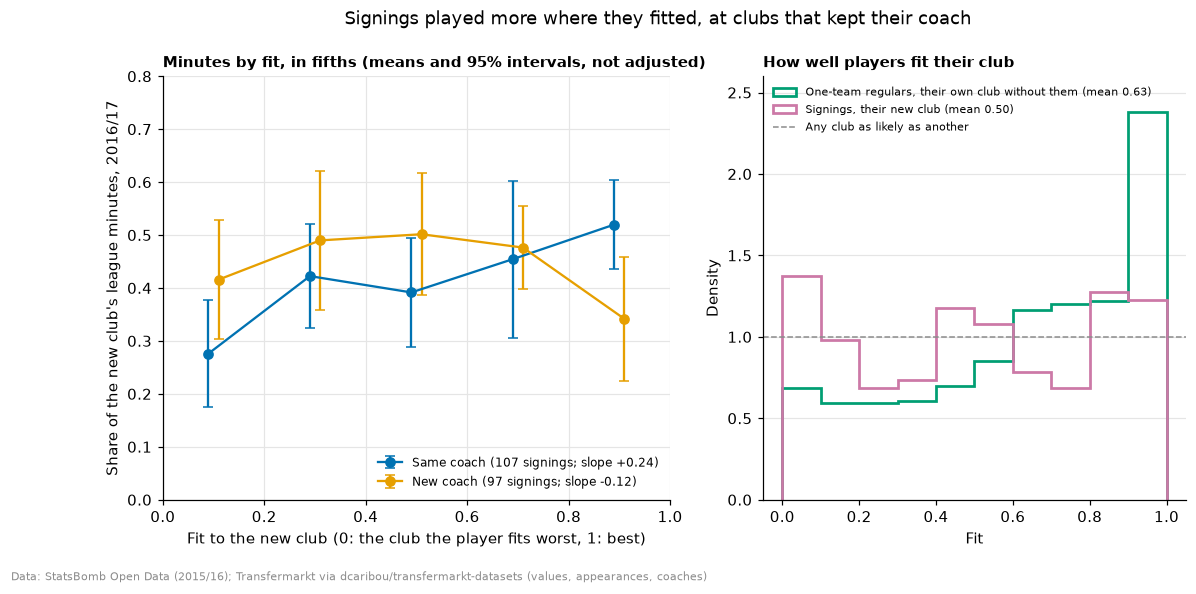

In [17]:
BANDS = np.linspace(0, 1, 6)
band = pd.cut(fits[FIT], BANDS, include_lowest=True, labels=False)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.2, 1]})
for i, (kept_coach, label) in enumerate([(True, "Same coach"), (False, "New coach")]):
    k = (signings.same_coach == kept_coach).to_numpy()
    by_band = signings.share[k].groupby(band[k]).agg(["mean", "std", "count"])
    middle = (BANDS[:-1] + BANDS[1:]) / 2
    x = middle[by_band.index] + (i - 0.5) * 0.02
    half = 1.96 * by_band["std"] / np.sqrt(by_band["count"])
    ax.errorbar(x, by_band["mean"], yerr=half, color=OKABE_ITO[i], marker="o", ms=6, lw=1.5,
                capsize=3, label=f"{label} ({k.sum()} signings; slope "
                f"{results[FIT].at[label, 'Slope']:+.2f})")  # fmt: skip
ax.set_xticks(BANDS)
ax.set_xlabel("Fit to the new club (0: the club the player fits worst, 1: best)")
ax.set_ylabel("Share of the new club's league minutes, 2016/17")
ax.set_ylim(0, 0.8)
ax.set_title("Minutes by fit, in fifths (means and 95% intervals, not adjusted)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax.grid(color="#E5E5E5")
bins = np.linspace(0, 1, 11)
ax2.hist(
    own_club,
    bins=bins,
    density=True,
    histtype="step",
    lw=1.8,
    color=OKABE_ITO[2],
    label=f"One-team regulars, their own club without them (mean {own_club.mean():.2f})",
)
ax2.hist(fits[FIT], bins=bins, density=True, histtype="step", lw=1.8, color=OKABE_ITO[3],
         label=f"Signings, their new club (mean {fits[FIT].mean():.2f})")  # fmt: skip
ax2.axhline(1, color=GREY, lw=1, ls="--", label="Any club as likely as another")
ax2.set_xlabel("Fit")
ax2.set_ylabel("Density")
ax2.set_ylim(0, 2.6)
ax2.set_title("How well players fit their club", fontsize=10)
ax2.legend(fontsize=7.5, loc="upper left")
fig.suptitle("Signings played more where they fitted, at clubs that kept their coach", y=1.0)
credit(fig, SOURCE + "; Transfermarkt via dcaribou/transfermarkt-datasets (values, appearances, "
            "coaches)")  # fmt: skip
plt.show()

In [18]:
kept = signings[signings.same_coach].assign(fit=fits[FIT])
shown = pd.concat([kept.nlargest(6, "fit"), kept.nsmallest(6, "fit")])
examples = pd.DataFrame({
    "Player": shown.index.map(player_names),
    "Group": shown.group.map(GROUP_NAMES),
    "From": team_names.team_name.loc[shown.old].to_numpy(),
    "To": team_names.team_name.loc[shown.new].to_numpy(),
    "Fit": shown.fit,
    "Value against the club's regulars": np.exp(shown.relative_value),
    "Share of league minutes": shown.share,
}).set_index("Player")  # fmt: skip
display(
    examples.style.format({"Fit": "{:.2f}", "Value against the club's regulars": "{:.1f}",
                           "Share of league minutes": "{:.0%}"})
    .set_caption("Signings for 2016/17 at clubs that kept their coach: the six best fits and the "
                 "six worst (value: the player's on 30 June 2016 over the median of the club's "
                 "2015/16 regulars)")
)  # fmt: skip
top, bottom = kept.fit >= 0.8, kept.fit <= 0.2
print(
    f"At clubs that kept their coach, the {top.sum()} signings with a fit of 0.8 or more played a "
    f"mean {kept.share[top].mean():.0%} of the league minutes, the {bottom.sum()} with 0.2 or less "
    f"{kept.share[bottom].mean():.0%}; their value against the club's regulars, a median "
    f"{np.exp(kept.relative_value[top].median()):.1f} and "
    f"{np.exp(kept.relative_value[bottom].median()):.1f}."
)

,Group,From,To,Fit,Value against the club's regulars,Share of league minutes
Player,,,,,,
Jean-Sylvain Claude Babin,Centre-backs,Granada,Sporting Gijón,1.00,1.8,50%
Lorenzo Tonelli,Centre-backs,Empoli,Napoli,1.00,0.3,8%
Younousse Sankharé,Central midfielders,Guingamp,Lille,0.99,1.5,46%
Henri Bedimo Nsamè,Full-backs,Lyon,Olympique de Marseille,0.97,0.4,34%
Eliaquim Mangala,Centre-backs,Manchester City,Valencia,0.96,2.3,77%
Wallace Fortuna dos Santos,Centre-backs,AS Monaco,Lazio,0.96,0.7,51%
Denis Suárez Fernández,Attacking midfielders and wingers,Villarreal,Barcelona,0.00,0.3,35%
Luis Hernández Rodríguez,Centre-backs,Sporting Gijón,Leicester City,0.01,0.4,10%
Brendan Joel Zibusiso Galloway,Full-backs,Everton,West Bromwich Albion,0.01,0.8,7%


At clubs that kept their coach, the 33 signings with a fit of 0.8 or more played a mean 52% of the league minutes, the 23 with 0.2 or less 28%; their value against the club's regulars, a median 1.0 and 0.7.


### What section 4 shows

- **The measure tells a club's style apart; clubs did not sign for it.** The one-team regulars
  fit their own club, without them, at a mean 0.63 against 0.5 for an average club (central
  midfielders 0.56 to full-backs 0.68, the groups the team shapes least and most in section 3).
  The 204 signings fit their new club at a mean 0.50 (0.46 to 0.55): clubs bought players no
  nearer their position's style than any other club's, as their signings came no nearer the
  player who left (notebook 06).
- **Over all signings, fit does not show in the minutes.** The slope is +0.08 of the club's league
  minutes from the worst-fitting club to the best (−0.04 to +0.19), within chance (12% of shuffles
  at or above it).
- **At clubs that kept their coach, it does; the split was not set out beforehand.** At the 37
  of 64 clubs whose coach went from the end of 2015/16 into 2016/17, a signing at the best-fitting
  club played 0.24 more of the league minutes than at the worst (0.10 to 0.39; 0.3% of shuffles at
  or above), with their value, age, minutes and group held equal; at clubs with a new coach, −0.12
  (−0.29 to +0.03). The gap, 0.36 (0.15 to 0.58), is above chance (0.2% of shuffles). Not
  adjusted, signings with a fit of 0.8 or more played 52% of the minutes at clubs that kept their
  coach, those with 0.2 or less 28%. The split follows from how fit is read (a club's style is its
  coach's as much as its players') but was added once the data showed the coaches, so it is the
  result to test again on another season.
- **The checks agree.** Without the change the team axes predict, the slope with the same coach is
  +0.20 and the gap +0.27; as recorded, +0.24 and +0.35; with the step in team strength as a
  further control (moving to a stronger team costs minutes, and is unrelated to fit: correlation
  −0.05), +0.20 and +0.30. Value counts too: a player valued at twice the median of the club's
  regulars played 9% more of its minutes.
- **The worst fits at clubs that kept their coach were moves up.** Denis Suárez and Paco Alcácer to
  Barcelona, Marco Asensio to Real Madrid, Lucas Pérez to Arsenal: players whose descriptors were
  far from how those clubs' players in their position played, and who played 8% to 35% of the
  league minutes. Among the best fits, Eliaquim Mangala played 77% at Valencia and Wallace 51% at
  Lazio; Lorenzo Tonelli, valued at a third of Napoli's regulars, 8%.
- **Limits.** 204 signings, 107 at clubs that kept their coach: the intervals are wide. A coach
  kept from one season to the next is the reading's condition; with a new coach the 2015/16 style
  says nothing, and its slope leans negative without leaving chance. Fit is read in the player's
  2015/16 position: a signing used elsewhere is measured against the wrong players. Adem Ljajić and
  Iago Falqué, who joined Torino, are left out: Torino played no attacking midfielder or winger in
  2015/16, and changed coach for 2016/17.

## 5. Against which opponents (an addendum)

Whether a player's numbers depend on the opponent's style in a way of their own, so that a
line-up could be picked for the opponent: a central midfielder who intercepts more than others
against teams that risk their passes, say. Read on the profiled players with 1,800 minutes or more
(two halves of 900, as for the profiles' reliability, notebook 02), through their group's twelve
profile statistics.

- **The opponent's style**: its scores on the two team style axes and its pass ease (section 1),
  from its matches against the other teams (its two against the player's team left out).
- **A player's response**: each team's 19 opponents are split at the median on each of the three
  (nine above, nine below, the median opponent left out), and the statistic is read from the
  player's matches against each half, on the profile's terms (counts rescaled for their recording
  context, on an even share of possession) and not shrunk. The response is the value against the
  upper half less the value against the lower half. Comparing a player with themselves takes out
  their level; the even share takes out what the opponent changes in their team's share of the
  ball.
- **Its reliability**: each player's matches against each half of the opponents are shuffled and
  dealt alternately into two halves (200 draws); the two halves' responses are correlated across
  the group's players and stepped up to a season (Spearman-Brown), as the team numbers were. The
  level of the same statistic, from the same halves, says how well the halves tell players apart.
  Chance: the 95th percentile of the same with each player's matches shuffled between the two
  halves of the opponents (200 shuffles of 10 draws).
- **The bar**: a response could guide a line-up with a reliability of 0.7 or more over a season,
  the bar of the team numbers and the style axes; players are shown only for such responses. A
  team's own answer to an opponent, shared by its players, counts here as each player's, so the
  reliabilities are an upper bound for a player's own.
- **What the opponent does to everyone**: the group's mean response over the season, in standard
  deviations of the players' values, with an interval from 2,000 resamples of the teams (each
  player with the team they played most for). The opponents at the high end of each axis are also
  the stronger (section 2).

### 5.1 A player's response to the opponent

In [19]:
counts = match_counts(con, cfg, {m for ms in cfg.profiles.values() for m in ms})
counts = counts[counts.player_id.isin(group.index)]
profile_tables = {
    t: con.sql(f"SELECT * FROM {t}").df() for t in ("profile_statistics", "profile_recording")
}  # fmt: skip
counts = rescale_players(counts, group, recording_context(counts, cfg),
                         profile_tables["profile_recording"])  # fmt: skip
PROFILE_SUMS = summed_columns(counts)
not_shrunk_profile = profile_tables["profile_statistics"].assign(k=0.0)

FACING = {  # the opponent's style: (low end, high end)
    "axis 1": AXIS_NAMES[1],
    "axis 2": AXIS_NAMES[2],
    "pass ease": ("Riskier passing", "Safer passing"),
}
head_to_head = adjusted.groupby(["team_id", "opponent_id"]).sum(numeric_only=True)
others = (
    season_sums.loc[head_to_head.index.get_level_values("team_id")].set_axis(head_to_head.index)
    - head_to_head
)  # each team without its matches against each opponent
others_numbers = numbers(others)
opponent = pd.concat([axes.scores(others_numbers[TEAM_NUMBERS]), others_numbers.pass_ease],
                     axis=1).set_axis(list(FACING), axis=1)  # fmt: skip
opponent.index = opponent.index.set_names(["opponent_id", "team_id"])  # as the team's opponent
side = np.sign(opponent - opponent.groupby(level="team_id").transform("median")).astype(int)
assert (side.groupby(level="team_id").apply(lambda s: (s == 1).sum()) == 9).all().all()
facing = counts[["match_id", "team_id"]].merge(
    sums[["match_id", "team_id", "opponent_id"]], on=["match_id", "team_id"], how="left"
)
counts["opponent_id"] = facing.opponent_id.to_numpy()
counts = counts.join(side, on=["opponent_id", "team_id"])
assert counts[list(FACING)].notna().all().all()

RESPONSE_MINUTES = 2 * RELIABILITY_MINUTES
SHUFFLE_DRAWS = 10


def deal(cells, rng):
    """Each row's half: the rows of each cell shuffled and dealt alternately from a random start."""
    order = np.lexsort((rng.random(len(cells)), cells))
    first = np.r_[0, np.flatnonzero(np.diff(cells[order])) + 1]
    rank = np.arange(len(cells)) - np.repeat(first, np.diff(np.r_[first, len(cells)]))
    half = np.empty(len(cells), dtype=int)
    half[order] = rank
    return (half + rng.integers(0, 2, cells.max() + 1)[cells]) % 2


def half_values(row_sums, player, upper, halves, g):
    """Group g's profile on its terms, not shrunk, from the rows' sums `row_sums`, for each draw
    (a row of `halves`), player (codes), half and half of the opponents (`upper`): draws x players
    x 2 x 2 x statistics; and the level, both halves of the opponents together: draws x players x
    2 x statistics."""
    draws, n = halves.shape
    players = player.max() + 1
    cell = ((np.arange(draws)[:, None] * players + player) * 2 + halves) * 2 + upper
    pick = sparse.csr_matrix((np.ones(draws * n), (cell.ravel(), np.tile(np.arange(n), draws))),
                             shape=(draws * players * 4, n))  # fmt: skip
    summed = (pick @ row_sums).reshape(draws, players, 2, 2, -1)

    def placed(s):
        frame = pd.DataFrame(s.reshape(-1, s.shape[-1]), columns=PROFILE_SUMS)
        return place_profile(frame, g, not_shrunk_profile).to_numpy().reshape(*s.shape[:-1], -1)

    return placed(summed), placed(summed.sum(axis=3))


def stepped(a, b):
    """The Pearson correlation of two halves' values across players (axis 1), per draw and
    statistic, stepped up to a season (Spearman-Brown)."""
    a, b = a - a.mean(axis=1, keepdims=True), b - b.mean(axis=1, keepdims=True)
    r = (a * b).sum(axis=1) / np.sqrt((a**2).sum(axis=1) * (b**2).sum(axis=1))
    return 2 * r / (1 + r)


EXAMPLE = ("CM", "interceptions", "pass ease")  # a midfielder against riskier passing


def lowered(label):
    """A label inside a sentence: "open-play passes", "xT gained"."""
    return label[:1].lower() + label[1:]


main_team = counts.groupby(["player_id", "team_id"]).minutes.sum().groupby(level=0).idxmax().str[1]
rng = np.random.default_rng(SEED)
responses, everyone, example = [], [], {}
for g in OUTFIELD:
    ids = profiled.index[(group.loc[profiled.index] == g).to_numpy()
                         & (profiled.minutes >= RESPONSE_MINUTES).to_numpy()]  # fmt: skip
    statistics = list(cfg.profiles[g])
    teams_at = pd.Index(main_team.loc[ids].unique())
    team_draws = np.array([np.bincount(rng.integers(0, len(teams_at), len(teams_at)),
                                       minlength=len(teams_at)) for _ in range(2000)])  # fmt: skip
    weights = team_draws[:, teams_at.get_indexer(main_team.loc[ids])]
    for f in FACING:
        r = counts[counts.player_id.isin(ids) & (counts[f] != 0)]
        row_sums = r[PROFILE_SUMS].to_numpy(float)
        player = pd.Index(ids).get_indexer(r.player_id)
        upper = (r[f] > 0).to_numpy(int)
        halves = np.array([deal(player * 2 + upper, rng) for _ in range(DRAWS)])
        values, level = half_values(row_sums, player, upper, halves, g)
        response = values[:, :, :, 1] - values[:, :, :, 0]
        reliability_draws = stepped(response[:, :, 0], response[:, :, 1])
        by_player = np.argsort(player, kind="stable")
        null = []
        for _ in range(DRAWS):
            shuffled = np.empty_like(upper)
            shuffled[by_player] = upper[np.lexsort((rng.random(len(upper)), player))]
            h = np.array([deal(player * 2 + shuffled, rng) for _ in range(SHUFFLE_DRAWS)])
            v = half_values(row_sums, player, shuffled, h, g)[0]
            null.append(
                stepped(v[:, :, 0, 1] - v[:, :, 0, 0], v[:, :, 1, 1] - v[:, :, 1, 0]).mean(axis=0)
            )
        season_values = place_profile(r.groupby(["player_id", f])[PROFILE_SUMS].sum(), g,
                                      not_shrunk_profile)  # fmt: skip
        season_level = place_profile(r.groupby("player_id")[PROFILE_SUMS].sum(), g,
                                     not_shrunk_profile)  # fmt: skip
        season_response = (season_values.xs(1, level=f) - season_values.xs(-1, level=f)).loc[ids]
        season_response = (season_response / season_level.std()).to_numpy()
        means = weights @ season_response / weights.sum(axis=1, keepdims=True)
        responses.append(pd.DataFrame({
            "group": g, "facing": f, "statistic": statistics, "players": len(ids),
            "matches": np.median(np.bincount(player * 2 + upper)),
            "reliability": reliability_draws.mean(axis=0),
            "chance": np.quantile(null, 0.95, axis=0),
            "level": stepped(level[:, :, 0], level[:, :, 1]).mean(axis=0),
            "everyone": season_response.mean(axis=0),
            "low": np.quantile(means, 0.025, axis=0), "high": np.quantile(means, 0.975, axis=0),
        }))  # fmt: skip
        if (g, f) == (EXAMPLE[0], EXAMPLE[2]):
            m = statistics.index(EXAMPLE[1])
            example = {"level": level[0, :, :, m], "response": response[0, :, :, m],
                       "reliability": reliability_draws[:, m].mean()}  # fmt: skip
responses = pd.concat(responses, ignore_index=True)
responses["above chance"] = responses.reliability > responses.chance
responses["moves everyone"] = (responses.low > 0) | (responses.high < 0)
by_group = responses.groupby("group").agg(
    players=("players", "first"), matches=("matches", "median"), level=("level", "median"),
    reliability=("reliability", "median"), top=("reliability", "max"),
    above=("above chance", "sum"), tests=("above chance", "size"),
).loc[OUTFIELD]  # fmt: skip
top_rows = responses.loc[responses.groupby("group").reliability.idxmax()].set_index("group")
response_table = pd.DataFrame({
    "Players": by_group.players,
    "Matches against each half (median)": by_group.matches,
    "Level: reliability (median)": by_group.level,
    "Response: reliability (median)": by_group.reliability,
    "Response: the most reliable": [
        f"{top_rows.reliability[g]:.2f}, {lowered(PROFILE_LABELS[top_rows.statistic[g]])} "
        f"against {FACING[top_rows.facing[g]][1].lower()}" for g in OUTFIELD
    ],
    "Above chance": [f"{a} of {t}" for a, t in zip(by_group.above, by_group.tests, strict=True)],
}).rename(index=GROUP_NAMES)  # fmt: skip
display(
    response_table.style.format("{:.2f}", subset=["Level: reliability (median)",
                                           "Response: reliability (median)"])
    .format("{:.0f}", subset="Matches against each half (median)")
    .set_caption("How reliably a player's response to the opponent's style tells players apart "
                 "over a season, against their level from the same halves (12 profile statistics "
                 "against each of the three, 200 draws; chance: 95th percentile of 200 shuffles "
                 "of the opponents' halves)")
)  # fmt: skip
best = responses.loc[responses.reliability.idxmax()]
seasons = (0.7 / 0.3) / (best.reliability / (1 - best.reliability))
shifted = responses[responses["moves everyone"]]
season_style = pd.concat([scores, season.pass_ease], axis=1).set_axis(list(FACING), axis=1)
close = opponent.corrwith(
    season_style.loc[opponent.index.get_level_values("opponent_id")].set_axis(opponent.index)
)
print(
    "Opponents' styles without their two matches against the team correlate "
    + ", ".join(f"{close[f]:.3f}" for f in FACING)
    + " with their season's; pass ease goes with axis 1 "
    f"({opponent['axis 1'].corr(opponent['pass ease']):+.2f}). Responses above chance: "
    f"{responses['above chance'].sum()} of {len(responses)} (by chance, about "
    f"{0.05 * len(responses):.0f}); the most reliable, {best.reliability:.2f} "
    f"({GROUP_NAMES[best.group].lower()}, {lowered(PROFILE_LABELS[best.statistic])} against "
    f"{FACING[best.facing][1].lower()}), would need about {seasons:.0f} seasons to reach 0.7. "
    f"The opponent moves everyone's numbers: {len(shifted)} of {len(responses)} mean responses "
    f"have an interval clear of 0, the largest "
    + "; ".join(
        f"{GROUP_NAMES[row.group].lower()}' {lowered(PROFILE_LABELS[row.statistic])} against "
        f"{FACING[row.facing][1].lower()} {row.everyone:+.2f}"
        for row in shifted.reindex(shifted.everyone.abs().sort_values(ascending=False).index)
        .head(4).itertuples()
    )
    + " standard deviations."
)  # fmt: skip

,Players,Matches against each half (median),Level: reliability (median),Response: reliability (median),Response: the most reliable,Above chance
group,,,,,,
Centre-backs,181,14,0.81,0.04,"0.25, clearances against high press",6 of 36
Full-backs,148,14,0.84,-0.00,"0.20, pass completion above expected against high press",1 of 36
Central midfielders,204,15,0.86,0.05,"0.22, open-play passes against combination play",3 of 36
Attacking midfielders and wingers,141,15,0.85,0.00,"0.32, tackles against high press",3 of 36
Centre-forwards,90,16,0.85,-0.05,"0.14, xT gained against high press",0 of 36


Opponents' styles without their two matches against the team correlate 0.999, 0.995, 0.999 with their season's; pass ease goes with axis 1 (+0.88). Responses above chance: 13 of 180 (by chance, about 9); the most reliable, 0.32 (attacking midfielders and wingers, tackles against high press), would need about 5 seasons to reach 0.7. The opponent moves everyone's numbers: 82 of 180 mean responses have an interval clear of 0, the largest centre-backs' clearances against safer passing -1.08; centre-backs' aerial duels against combination play -1.05; centre-backs' aerial duels against safer passing -0.98; centre-backs' clearances against combination play -0.95 standard deviations.


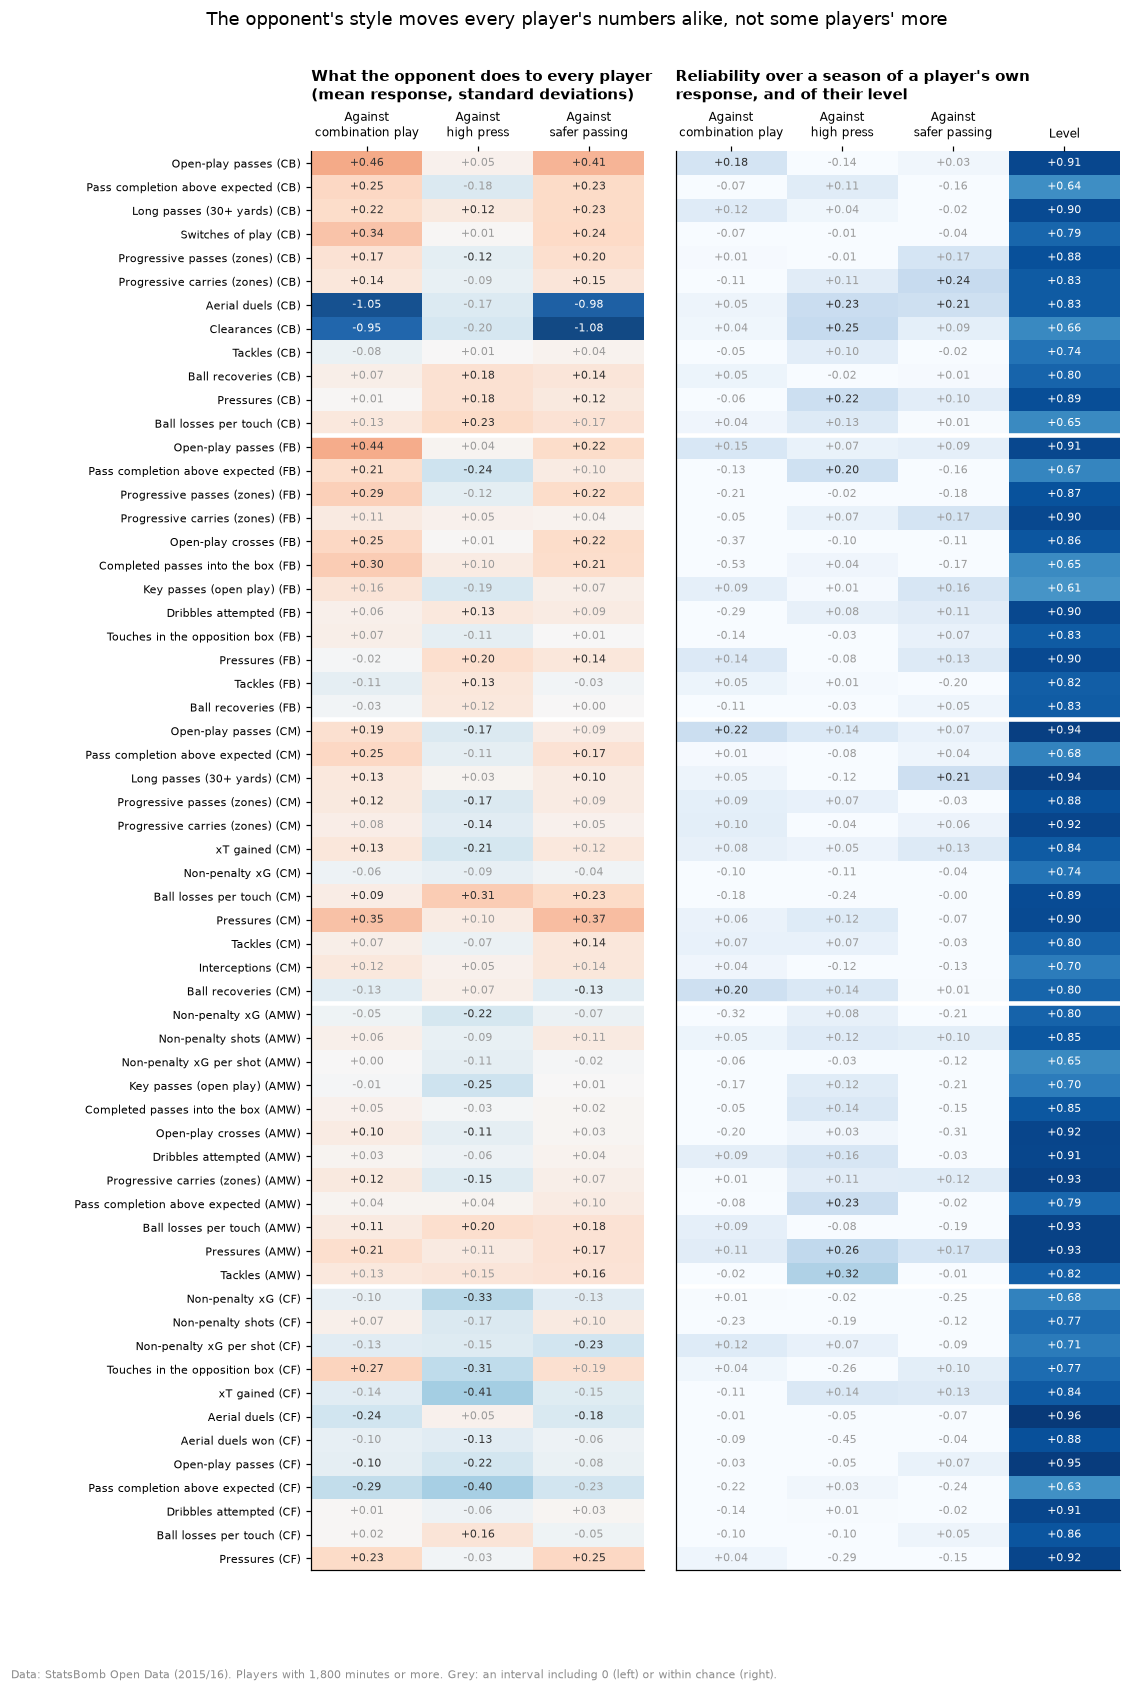

In [20]:
rows_shown = [(g, m) for g in OUTFIELD for m in cfg.profiles[g]]
grid = responses.set_index(["group", "statistic", "facing"]).sort_index()
fig, axs = plt.subplots(1, 2, figsize=(10.5, 15), gridspec_kw={"width_ratios": [3, 4]})
fig.subplots_adjust(left=0.27, right=0.97, top=0.9, bottom=0.04, wspace=0.08)
panels = [  # the value shown, its columns, colour map and range, title, when it is not grey
    ("everyone", list(FACING), "RdBu_r", (-1.2, 1.2), "What the opponent does to every player\n"
     "(mean response, standard deviations)", "moves everyone"),
    ("reliability", [*FACING, "level"], "Blues", (0, 1), "Reliability over a season of a "
     "player's own\nresponse, and of their level", "above chance"),
]  # fmt: skip
for ax, (column, columns, cmap, (low, high), title, shown) in zip(axs, panels, strict=True):
    table = np.array([[grid.loc[(g, m, f), column] if f in FACING
                       else grid.loc[(g, m), "level"].mean() for f in columns]
                      for g, m in rows_shown])  # fmt: skip
    strong = np.array([[grid.loc[(g, m, f), shown] if f in FACING else True for f in columns]
                       for g, m in rows_shown])  # fmt: skip
    ax.imshow(table, cmap=cmap, vmin=low, vmax=high, aspect="auto")
    for i in range(len(rows_shown)):
        for j in range(len(columns)):
            value = table[i, j]
            color = (
                ("white" if abs(value) >= 0.6 * high else "#333333")
                if strong[i, j]
                else ("#9A9A9A")
            )
            ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(range(len(columns)), [f"Against\n{FACING[f][1].lower()}" if f in FACING
                                        else "Level" for f in columns], fontsize=8)  # fmt: skip
    ax.xaxis.tick_top()
    for k in range(1, len(OUTFIELD)):
        ax.axhline(12 * k - 0.5, color="white", lw=3)
    ax.set_title(title, fontsize=10, pad=34)
    ax.grid(False)
    ax.set_yticks([])
axs[0].set_yticks(range(len(rows_shown)),
                  [f"{PROFILE_LABELS[m]} ({g})" for g, m in rows_shown], fontsize=7.5)  # fmt: skip
fig.suptitle("The opponent's style moves every player's numbers alike, not some players' more",
             y=0.985)  # fmt: skip
credit(fig, SOURCE + ". Players with 1,800 minutes or more. Grey: an interval including 0 (left) "
            "or within chance (right).")  # fmt: skip
plt.show()

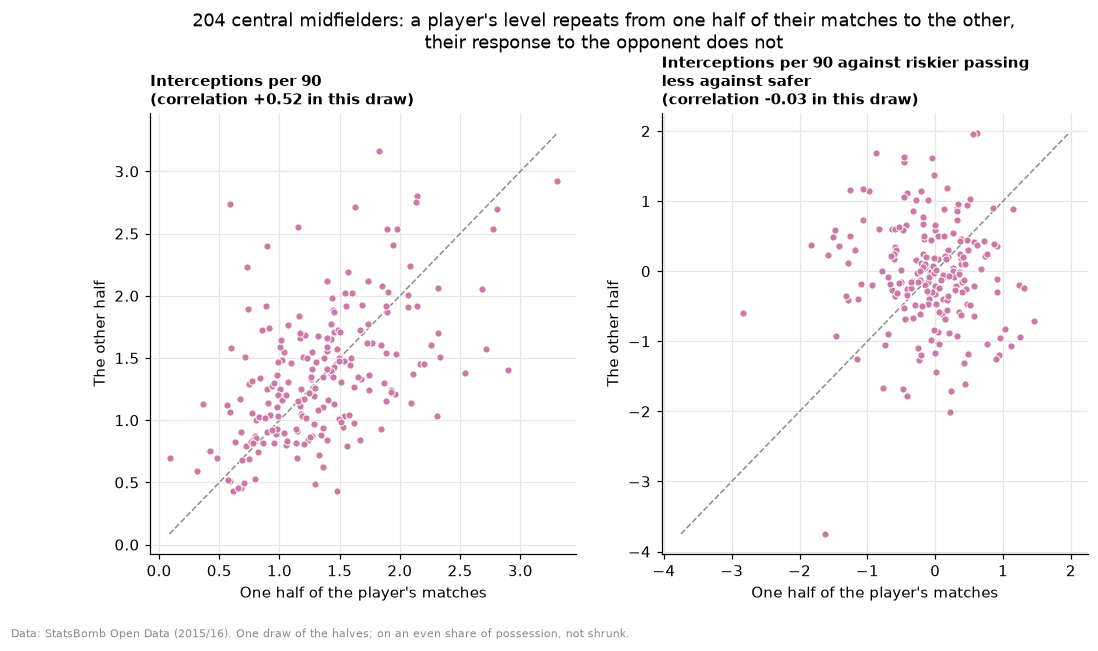

Central midfielders' interceptions against riskier passing less against safer: a reliability of -0.13 over a season (mean of 200 draws), against 0.70 for their level.


In [21]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (key, title, sign) in zip(axs, [
    ("level", "Interceptions per 90", 1),
    ("response", "Interceptions per 90 against riskier passing\nless against safer", -1),
], strict=True):  # fmt: skip
    a, b = sign * example[key][:, 0], sign * example[key][:, 1]
    ax.scatter(a, b, s=22, color=GROUP_COLORS["CM"], edgecolor="white", linewidth=0.6, zorder=3)
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ax.plot([lo, hi], [lo, hi], color=GREY, lw=1, ls="--")
    ax.set_xlabel("One half of the player's matches")
    ax.set_ylabel("The other half")
    r = np.corrcoef(a, b)[0, 1]
    ax.set_title(f"{title}\n(correlation {r:+.2f} in this draw)", fontsize=10)
    ax.grid(color="#E5E5E5")
fig.suptitle(f"{len(example['level'])} central midfielders: a player's level repeats from one "
             "half of their matches to the other,\ntheir response to the opponent does not",
             y=1.06)  # fmt: skip
credit(fig, SOURCE + ". One draw of the halves; on an even share of possession, not shrunk.")
plt.show()
print(
    f"Central midfielders' interceptions against riskier passing less against safer: a reliability "
    f"of {example['reliability']:.2f} over a season (mean of {DRAWS} draws), against "
    f"{grid.loc[EXAMPLE[:2], 'level'].mean():.2f} for their level."
)

### What section 5 shows

- **No player answers the opponent's style in a way of their own that one season can see.** Over
  180 responses (the twelve profile statistics of five groups, against each of the three sides of
  the opponent's style), the median reliability over a season is −0.05 to +0.05 by group. The most
  reliable, attacking midfielders' and wingers' tackles against a high press, 0.32, would take
  about five seasons to reach 0.7. Thirteen are above chance, where about nine would be by chance
  alone. The same halves tell players' levels apart at a median 0.81 to 0.86.
- **The example fails too.** A central midfielder's interceptions against riskier passing, less
  against safer: a reliability of −0.13, against 0.70 for their level of interceptions.
- **The opponent moves everyone's numbers alike.** 82 of the 180 mean responses have an interval
  clear of 0. Against direct teams centre-backs make about a standard deviation more aerial duels
  and clearances (−1.05 and −0.95 against combination play, −0.98 and −1.08 against safer
  passing), and they pass more against teams that combine (+0.46); against a high press,
  centre-forwards gain less xT (−0.41) and complete fewer passes than expected (−0.40). These
  shifts are the opponent's, on an even share of possession, and partly its strength.
- **What a line-up can be fitted to.** The opponent changes what a match asks of a position, and
  players differ reliably in their level; a line-up fitted to the opponent goes through those two,
  such as the centre-backs strongest in the air against a direct team. A player's own response to
  an opponent's style is not something one season of data can pick players by.
- **Limits.** Each player's matches against nine opponents on each side, 14 to 16 matches against
  each; a team's shared answer to an opponent counts as each of its players', so the reliabilities
  are an upper bound for a player's own; and the statistics are on an even share of possession,
  which takes out what an opponent changes in a team's share of the ball.